# M/GI/1 Gamma-Service Stationary Performance Experiment

## Main research task

The main ML task is **configuration-level steady-state performance prediction**:

$$
(\rho,\; \mathrm{SCV}_S) \longrightarrow W_q,
$$

with the mean service time initially fixed at

$$
E[S]=1.
$$

Each **queue configuration contributes one ML row**. For each configuration, 30 independent simulation replications are aggregated to estimate the steady-state mean waiting time and its simulation uncertainty. The exact Pollaczek--Khinchine mean is retained as an analytical reference, not as a training label.

### Workflow

1. Validate the Gamma-service M/GI/1 simulator against the Pollaczek--Khinchine benchmark.
2. Use the reliability pilot to justify a common fixed-time design of **10,000 warm-up + 40,000 recording time units**.
3. Retain the original 18 configurations as simulator-validation anchors.
4. Start the stationary ML experiment with a **200-configuration** $(\rho,\mathrm{SCV})$ grid. The adequacy of 200 configurations is treated as an empirical question; the same pipeline can be expanded to 300--400 configurations if model stability indicates that more coverage is useful.
5. Split **configurations**, never replications, into training, validation, and final test sets. All models use the same held-out configurations.
6. Train Linear Regression, Decision Tree, Random Forest, and XGBoost on the same raw inputs $(\rho,\mathrm{SCV}_S)$, using validation configurations for model/hyperparameter selection only.
7. Evaluate on the untouched test configurations using absolute and relative errors, predicted-versus-theoretical comparisons, and errors across utilisation and SCV.
8. Report simulation uncertainty separately from ML prediction error, and keep simulation, training, and prediction timing separate.

The earlier interval-level forecasting results remain supplementary and are not extended here. Correlated-service M/G/1 experiments are deferred; the next queueing-model stage can proceed directly beyond this Gamma-service experiment.


## 1. Setup and experiment controls


In [1]:
from pathlib import Path
import json
import math
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import t as student_t
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

# -----------------------------
# Queue and simulation settings
# -----------------------------
SERVICE_MEAN = 1.0
BASE_SEED = 123
DT = 1.0
N_REPLICATIONS = 30

# Final fixed-time design confirmed after the reliability pilot
SIM_WARMUP_TIME = 10_000.0
SIM_RECORD_TIME = 40_000.0

# Reliability pilot
PILOT_RHOS = [0.30, 0.70, 0.95]
PILOT_SCVS = [0.25, 1.00, 2.00]
PILOT_REPLICATIONS = 30

# Original 18 simulator-validation anchors
ANCHOR_RHOS = [0.30, 0.50, 0.70, 0.80, 0.90, 0.95]
ANCHOR_SCVS = [0.25, 1.00, 2.00]

# Configuration-level split proportions.
# For the current 200-row design these reproduce 140/30/30 exactly.
TRAIN_FRACTION = 0.70
VALIDATION_FRACTION = 0.15
TEST_FRACTION = 0.15

OUTPUT_DIR = Path("MGI1_stationary_revised")
OUTPUT_DIR.mkdir(exist_ok=True)


## 2. Queueing formulas and Gamma service distribution

For an M/GI/1 queue,

$$
\rho=\lambda E[S] < 1,
$$

and the Pollaczek--Khinchine mean waiting time is

$$
W_q=\frac{\lambda E[S^2]}{2(1-\rho)}.
$$

With \(E[S]=1\) and service-time SCV \(c_s^2\),

$$
E[S^2]=1+c_s^2,\qquad \lambda=\rho,
$$

so

$$
W_q=\frac{\rho(1+c_s^2)}{2(1-\rho)}.
$$

The corresponding mean queue length is obtained by Little's Law,

$$
L_q=\lambda W_q.
$$

Gamma service times are parameterised so that their mean remains 1 while SCV varies. When $\mathrm{SCV}=1$, the Gamma distribution reduces to the **exponential distribution, giving the M/M/1 special case**.

In [2]:
def gamma_service_parameters(service_mean, service_scv):
    if service_mean <= 0:
        raise ValueError("service_mean must be positive")
    if service_scv <= 0:
        raise ValueError("service_scv must be positive")

    shape = 1.0 / service_scv # k values
    scale = service_mean / shape  # = service_mean * service_scv, theta
    return shape, scale


def gamma_service_moments(service_mean, service_scv):
    variance = service_scv * service_mean**2  ## =1/k
    second_moment = variance + service_mean**2 ## = 1+SCV
    return {
        "mean": service_mean,
        "variance": variance,
        "second_moment": second_moment,
        "scv": service_scv,
    }


def mgi1_theory(rho, service_scv, service_mean=1.0):
    if not (0 < rho < 1):
        raise ValueError("Stable M/GI/1 requires 0 < rho < 1")

    lam = rho / service_mean
    moments = gamma_service_moments(service_mean, service_scv)

    wq = lam * moments["second_moment"] / (2.0 * (1.0 - rho))
    w = wq + service_mean
    lq = lam * wq
    l = lam * w

    return {
        "rho": rho,
        "lambda_rate": lam,
        "service_mean": service_mean,
        "service_scv": service_scv,
        "service_second_moment": moments["second_moment"],
        "Wq_theory": wq,
        "W_theory": w,
        "Lq_theory": lq,
        "L_theory": l,
    }


## 3. Fixed-time M/GI/1 simulator

The simulation runs continuously from time zero through the end of the recording horizon. The initial interval $[0,T_{\mathrm{warm}})$ is used as warm-up. The measurement cohort consists of customers **arriving during the recording window**

$$
[T_{\mathrm{warm}},\;T_{\mathrm{warm}}+T_{\mathrm{record}}).
$$

These customers are followed until service completion even when their departure occurs after the end of the recording window. This avoids truncating their waiting times. Arrivals after the recording horizon are not required because FCFS customers arriving later cannot affect the waiting times of the measurement cohort.

The stationary target is the customer-level $W_q$, so an interval grid is not required to calculate the label. `DT = 1` is retained only as a common time-unit convention for compatibility with supplementary work.


### 3.1 Simulator Construction

In [3]:
def generate_poisson_arrivals_until(rng, lambda_rate, end_time):
    """Generate exponential interarrival times until end_time."""
    expected = lambda_rate * end_time
    n_initial = max(
        100,
        int(expected + 12.0 * math.sqrt(max(expected, 1.0)) + 100)
    )

    interarrival = rng.exponential(
        scale=1.0 / lambda_rate,
        size=n_initial
    )
    arrivals = np.cumsum(interarrival)

    while arrivals[-1] < end_time:
        batch_size = max(100, int(0.05 * n_initial))
        extra = rng.exponential(
            scale=1.0 / lambda_rate,
            size=batch_size
        )
        arrivals = np.concatenate([
            arrivals,
            arrivals[-1] + np.cumsum(extra)
        ])

    return arrivals[arrivals < end_time]


def simulate_mgi1_fixed_time(
    rho,
    service_scv,
    service_mean=1.0,
    warmup_time=SIM_WARMUP_TIME,
    record_time=SIM_RECORD_TIME,
    seed=123,
):
    """
    Fixed-time M/GI/1 simulation.

    Returns one replication-level stationary estimate. The primary estimate is
    Wq for customers arriving in the recording window.
    """
    if not (0 < rho < 1):
        raise ValueError("rho must lie in (0, 1)")

    rng = np.random.default_rng(seed)
    lambda_rate = rho / service_mean
    horizon_end = warmup_time + record_time

    arrival_time = generate_poisson_arrivals_until(
        rng=rng,
        lambda_rate=lambda_rate,
        end_time=horizon_end,)
    n_customers = len(arrival_time)

    shape, scale = gamma_service_parameters(
        service_mean=service_mean,
        service_scv=service_scv,)
    service_time = rng.gamma(
        shape=shape,
        scale=scale,
        size=n_customers,)

    # Vectorised equivalent of:
    # B_i = max(X_i, D_{i-1}), D_i = B_i + S_i
    cumulative_service = np.cumsum(service_time)
    cumulative_before = np.empty(n_customers)
    cumulative_before[0] = 0.0
    cumulative_before[1:] = cumulative_service[:-1]

    running_offset = np.maximum.accumulate(
        arrival_time - cumulative_before
    )
    departure_time = cumulative_service + running_offset
    service_start = departure_time - service_time

    waiting_time = service_start - arrival_time
    system_time = departure_time - arrival_time

    cohort = (
        (arrival_time >= warmup_time)
        & (arrival_time < horizon_end)
    )

    if cohort.sum() == 0:
        raise RuntimeError("No arrivals in recording cohort")

    cohort_service = service_time[cohort]
    cohort_wait = waiting_time[cohort]
    cohort_system = system_time[cohort]

    lambda_hat = cohort.sum() / record_time
    service_mean_hat = cohort_service.mean()
    service_var_hat = cohort_service.var(ddof=0)
    service_scv_hat = service_var_hat / service_mean_hat**2

    return {
        "Wq_sim": float(cohort_wait.mean()),
        "W_sim": float(cohort_system.mean()),
        "lambda_hat": float(lambda_hat),
        "service_mean_hat": float(service_mean_hat),
        "service_scv_hat": float(service_scv_hat),
        "n_record_arrivals": int(cohort.sum()),
        "n_generated_arrivals": int(n_customers),
    }


### 3.2 Quick simulator check

In [4]:
# A light check only; this is not used as a final result.
check = simulate_mgi1_fixed_time(
    rho=0.70,
    service_scv=1.00,
    service_mean=SERVICE_MEAN,
    warmup_time=1_000,
    record_time=2_000,
    seed=BASE_SEED,
)

check_theory = mgi1_theory(
    rho=0.70,
    service_scv=1.00,
    service_mean=SERVICE_MEAN,
)

pd.DataFrame([{**check_theory, **check}]).round(4)


,rho,lambda_rate,service_mean,service_scv,service_second_moment,Wq_theory,W_theory,Lq_theory,L_theory,Wq_sim,W_sim,lambda_hat,service_mean_hat,service_scv_hat,n_record_arrivals,n_generated_arrivals
0,0.7,0.7,1.0,1.0,2.0,2.3333,3.3333,1.6333,2.3333,2.0357,3.0377,0.6945,1.002,0.9958,1389,2129


## 4. Replications, uncertainty, and configuration-level labels

For the main stationary task, the 30 replications at one $(\rho,\mathrm{SCV})$ configuration are **not 30 ML rows**. They are combined to estimate one stationary label and its uncertainty.

For $R$ independent replication means $\hat W_{q,1},\ldots,\hat W_{q,R}$, the 95% Student-$t$ interval is

$$
\bar W_q \pm t_{0.975,R-1}\frac{s}{\sqrt{R}},
$$

where \(s\) is the standard deviation of the **replication-level estimates**. For \(R=30\), $t_{0.975,29}\approx2.045$.


In [5]:
def run_replications_for_config(
    config_id,
    rho,
    service_scv,
    replications=N_REPLICATIONS,
    warmup_time=SIM_WARMUP_TIME,
    record_time=SIM_RECORD_TIME,
    service_mean=SERVICE_MEAN,
    base_seed=BASE_SEED,
    seed_offset=0,
):
    rows = []
    theory = mgi1_theory(
        rho=rho,
        service_scv=service_scv,
        service_mean=service_mean,
    )

    # Stable integer derived from configuration values, independent of Python hash().
    rho_code = int(round(rho * 10_000))
    scv_code = int(round(service_scv * 10_000))

    for rep in range(replications):
        seed = (
            int(base_seed)
            + int(seed_offset)
            + rho_code * 100_000
            + scv_code * 10
            + rep
        ) % (2**32 - 1)

        start = time.perf_counter()
        sim = simulate_mgi1_fixed_time(
            rho=rho,
            service_scv=service_scv,
            service_mean=service_mean,
            warmup_time=warmup_time,
            record_time=record_time,
            seed=seed,
        )
        elapsed = time.perf_counter() - start

        rows.append({
            "config_id": config_id,
            "rho": rho,
            "lambda_rate": theory["lambda_rate"],
            "service_mean": service_mean,
            "service_scv": service_scv,
            "warmup_time": warmup_time,
            "record_time": record_time,
            "replication": rep + 1,
            "seed": seed,
            "runtime_seconds": elapsed,
            "Wq_theory": theory["Wq_theory"],
            "Lq_theory": theory["Lq_theory"],
            **sim,
        })

    return pd.DataFrame(rows)

# W_q_sim(mean of replications), L_q_sim (Little's Law)
def aggregate_configuration_labels(replication_df):
    rows = []

    group_cols = [
        "config_id", "rho", "lambda_rate",
        "service_mean", "service_scv",
        "warmup_time", "record_time",
    ]

    for keys, g in replication_df.groupby(group_cols, sort=True):
        (
            config_id, rho, lambda_rate, service_mean,
            service_scv, warmup_time, record_time
        ) = keys

        wq = g["Wq_sim"].to_numpy(dtype=float)
        R = len(wq)
        mean = float(wq.mean())
        sd = float(wq.std(ddof=1)) if R > 1 else np.nan
        se = sd / math.sqrt(R) if R > 1 else np.nan
        tcrit = float(student_t.ppf(0.975, df=R-1)) if R > 1 else np.nan
        hw = tcrit * se if R > 1 else np.nan

        wq_theory = float(g["Wq_theory"].iloc[0])
        lq_theory = float(g["Lq_theory"].iloc[0])

        row = {
            "config_id": config_id,
            "rho": float(rho),
            "lambda_rate": float(lambda_rate),
            "service_mean": float(service_mean),
            "service_scv": float(service_scv),
            "warmup_time": float(warmup_time),
            "record_time": float(record_time),
            "n_replications": int(R),
            "Wq_theory": wq_theory,
            "Wq_sim_mean": mean,
            "Wq_rep_sd": sd,
            "Wq_se": se,
            "Wq_ci95_low": mean - hw,
            "Wq_ci95_high": mean + hw,
            "Wq_ci95_halfwidth": hw,
            "Wq_relative_ci_halfwidth_pct": (
                100.0 * hw / abs(mean) if mean != 0 else np.nan
            ),
            "Wq_abs_error_vs_theory": abs(mean - wq_theory),
            "Wq_rel_error_vs_theory_pct": (
                100.0 * abs(mean - wq_theory) / abs(wq_theory)
                if wq_theory != 0 else np.nan
            ),
            "Lq_theory": lq_theory,
            "Lq_sim_from_Wq": float(lambda_rate * mean),
            "Lq_ci95_low_from_Wq": float(lambda_rate * (mean - hw)),
            "Lq_ci95_high_from_Wq": float(lambda_rate * (mean + hw)),
            "lambda_hat_mean": float(g["lambda_hat"].mean()),
            "service_mean_hat_mean": float(g["service_mean_hat"].mean()),
            "service_scv_hat_mean": float(g["service_scv_hat"].mean()),
            "mean_runtime_seconds_per_rep": float(g["runtime_seconds"].mean()),
        }
        rows.append(row)

    return pd.DataFrame(rows)


## 5. Reliability pilot

The pilot spans low, moderate, and high utilisation and low, exponential, and high service variability:
$$
\rho\in\{0.30,0.70,0.95\},\qquad
\mathrm{SCV}\in\{0.25,1,2\}.
$$

Three simulation-length designs are compared:

1. baseline: 10,000 warm-up + 20,000 recording time units;
2. longer warm-up: 20,000 warm-up + 20,000 recording time units;
3. longer recording: 10,000 warm-up + 40,000 recording time units.

The pilot reports changes in the estimated mean and replication-level uncertainty. It is a diagnostic for label reliability; it does not automatically declare a configuration acceptable or unacceptable.


In [6]:
PILOT_DESIGNS = {
    "baseline": (10_000.0, 20_000.0),
    "longer_warmup": (20_000.0, 20_000.0),
    "longer_recording": (10_000.0, 40_000.0),
}

pilot_replications = None
pilot_summary = None

pilot_frames = []

for rho in PILOT_RHOS:
    for scv in PILOT_SCVS:
        for design_index, (design_name, (warm, record)) in enumerate(PILOT_DESIGNS.items()):
            config_id = f"pilot_rho{rho:.2f}_scv{scv:.2f}_{design_name}"
            print(f"Pilot: rho={rho:.2f}, SCV={scv:.2f}, {design_name}")

            tmp = run_replications_for_config(
                config_id=config_id,
                rho=rho,
                service_scv=scv,
                replications=PILOT_REPLICATIONS,
                warmup_time=warm,
                record_time=record,
                seed_offset=design_index * 10_000_000,
            )
            tmp["pilot_design"] = design_name
            pilot_frames.append(tmp)

pilot_replications = pd.concat(pilot_frames, ignore_index=True)
pilot_replications.to_csv(
    OUTPUT_DIR / "mgi1_reliability_pilot_replications.csv",
    index=False,
)

pilot_summary = aggregate_configuration_labels(pilot_replications)
pilot_summary = pilot_summary.merge(
    pilot_replications[["config_id", "pilot_design"]].drop_duplicates(),
    on="config_id",
    how="left",
)
pilot_summary.to_csv(
    OUTPUT_DIR / "mgi1_reliability_pilot_summary.csv",
    index=False,
)

display_cols = [
    "rho", "service_scv", "pilot_design",
    "Wq_theory", "Wq_sim_mean",
    "Wq_rep_sd", "Wq_ci95_halfwidth",
    "Wq_rel_error_vs_theory_pct",
]
display(pilot_summary[display_cols].sort_values(
    ["rho", "service_scv", "pilot_design"]
).round(4))


Pilot: rho=0.30, SCV=0.25, baseline
Pilot: rho=0.30, SCV=0.25, longer_warmup
Pilot: rho=0.30, SCV=0.25, longer_recording
Pilot: rho=0.30, SCV=1.00, baseline
Pilot: rho=0.30, SCV=1.00, longer_warmup
Pilot: rho=0.30, SCV=1.00, longer_recording
Pilot: rho=0.30, SCV=2.00, baseline
Pilot: rho=0.30, SCV=2.00, longer_warmup
Pilot: rho=0.30, SCV=2.00, longer_recording
Pilot: rho=0.70, SCV=0.25, baseline
Pilot: rho=0.70, SCV=0.25, longer_warmup
Pilot: rho=0.70, SCV=0.25, longer_recording
Pilot: rho=0.70, SCV=1.00, baseline
Pilot: rho=0.70, SCV=1.00, longer_warmup
Pilot: rho=0.70, SCV=1.00, longer_recording
Pilot: rho=0.70, SCV=2.00, baseline
Pilot: rho=0.70, SCV=2.00, longer_warmup
Pilot: rho=0.70, SCV=2.00, longer_recording
Pilot: rho=0.95, SCV=0.25, baseline
Pilot: rho=0.95, SCV=0.25, longer_warmup
Pilot: rho=0.95, SCV=0.25, longer_recording
Pilot: rho=0.95, SCV=1.00, baseline
Pilot: rho=0.95, SCV=1.00, longer_warmup
Pilot: rho=0.95, SCV=1.00, longer_recording
Pilot: rho=0.95, SCV=2.00, basel

,rho,service_scv,pilot_design,Wq_theory,Wq_sim_mean,Wq_rep_sd,Wq_ci95_halfwidth,Wq_rel_error_vs_theory_pct
0,0.30,0.25,baseline,0.2679,0.2660,0.0167,0.0063,0.6930
1,0.30,0.25,longer_recording,0.2679,0.2649,0.0092,0.0034,1.1117
2,0.30,0.25,longer_warmup,0.2679,0.2718,0.0118,0.0044,1.4786
3,0.30,1.00,baseline,0.4286,0.4342,0.0292,0.0109,1.3189
4,0.30,1.00,longer_recording,0.4286,0.4339,0.0180,0.0067,1.2371
5,0.30,1.00,longer_warmup,0.4286,0.4348,0.0264,0.0099,1.4426
6,0.30,2.00,baseline,0.6429,0.6370,0.0451,0.0168,0.9063
7,0.30,2.00,longer_recording,0.6429,0.6330,0.0232,0.0087,1.5388
8,0.30,2.00,longer_warmup,0.6429,0.6462,0.0611,0.0228,0.5181
9,0.70,0.25,baseline,1.4583,1.4598,0.0644,0.0241,0.0982


Pilot: rho=0.95, SCV=2.00, longer_warmup
Pilot: rho=0.95, SCV=2.00, longer_recording


,rho,service_scv,pilot_design,Wq_theory,Wq_sim_mean,Wq_rep_sd,Wq_ci95_halfwidth,Wq_rel_error_vs_theory_pct
0,0.30,0.25,baseline,0.2679,0.2660,0.0167,0.0063,0.6930
1,0.30,0.25,longer_recording,0.2679,0.2649,0.0092,0.0034,1.1117
2,0.30,0.25,longer_warmup,0.2679,0.2718,0.0118,0.0044,1.4786
3,0.30,1.00,baseline,0.4286,0.4342,0.0292,0.0109,1.3189
4,0.30,1.00,longer_recording,0.4286,0.4339,0.0180,0.0067,1.2371
5,0.30,1.00,longer_warmup,0.4286,0.4348,0.0264,0.0099,1.4426
6,0.30,2.00,baseline,0.6429,0.6370,0.0451,0.0168,0.9063
7,0.30,2.00,longer_recording,0.6429,0.6330,0.0232,0.0087,1.5388
8,0.30,2.00,longer_warmup,0.6429,0.6462,0.0611,0.0228,0.5181
9,0.70,0.25,baseline,1.4583,1.4598,0.0644,0.0241,0.0982


### 5.1 Pilot sensitivity summary


In [7]:
means = pilot_summary.pivot_table(
    index=["rho", "service_scv"],
    columns="pilot_design",
    values="Wq_sim_mean",
).reset_index()

for col in ["baseline", "longer_warmup", "longer_recording"]:
    if col not in means.columns:
        means[col] = np.nan

means["warmup_change_pct_vs_baseline"] = (
    100.0 * (means["longer_warmup"] - means["baseline"]).abs()
    / means["baseline"].abs()
)
means["recording_change_pct_vs_baseline"] = (
    100.0 * (means["longer_recording"] - means["baseline"]).abs()
    / means["baseline"].abs()
)

pilot_precision = pilot_summary.pivot_table(
    index=["rho", "service_scv"],
    columns="pilot_design",
    values="Wq_relative_ci_halfwidth_pct",
).reset_index()
pilot_precision.columns = [
    c if not isinstance(c, tuple) else "_".join([str(x) for x in c if x])
    for c in pilot_precision.columns
]

pilot_sensitivity = means.merge(
    pilot_precision,
    on=["rho", "service_scv"],
    how="left",
    suffixes=("", "_rel_ci_hw_pct"),
)

pilot_sensitivity.to_csv(
    OUTPUT_DIR / "mgi1_reliability_pilot_sensitivity.csv",
    index=False,
)

display(pilot_sensitivity.round(3))


,rho,service_scv,baseline,longer_recording,longer_warmup,warmup_change_pct_vs_baseline,recording_change_pct_vs_baseline,baseline_rel_ci_hw_pct,longer_recording_rel_ci_hw_pct,longer_warmup_rel_ci_hw_pct
0,0.30,0.25,0.266,0.265,0.272,2.187,0.422,2.350,1.297,1.624
1,0.30,1.00,0.434,0.434,0.435,0.122,0.081,2.515,1.549,2.269
2,0.30,2.00,0.637,0.633,0.646,1.438,0.638,2.644,1.370,3.531
3,0.70,0.25,1.460,1.451,1.441,1.269,0.619,1.648,1.048,1.980
4,0.70,1.00,2.371,2.308,2.349,0.926,2.640,2.188,1.516,2.399
5,0.70,2.00,3.501,3.543,3.588,2.505,1.213,2.801,1.923,3.409
6,0.95,0.25,11.365,11.783,11.782,3.666,3.675,6.864,5.585,7.560
7,0.95,1.00,19.867,18.758,19.085,3.934,5.580,12.262,5.610,9.926
8,0.95,2.00,33.604,28.076,29.296,12.821,16.451,14.323,4.599,12.524


## 6. Fixed-time validation on the original 18 anchor configurations

The original six utilisation values and three SCV values are retained as formal simulator-validation anchors. They are rerun using the final fixed-time design of **10,000 warm-up + 40,000 recording time units**, with 30 independent replications per configuration. The purpose is to verify agreement with the exact Pollaczek--Khinchine mean while displaying replication-level simulation uncertainty separately.


In [8]:
# Formal anchor validation under the final fixed-time design


# --------------------------------------------------------
# Build the 18 anchor configurations independently of the ML grid
# --------------------------------------------------------

anchor_configs = (
    pd.MultiIndex.from_product(
        [ANCHOR_RHOS, ANCHOR_SCVS],
        names=["rho", "service_scv"]
    )
    .to_frame(index=False)
)

anchor_configs.insert(
    0,
    "config_id",
    [
        f"anchor_rho{rho:.2f}_scv{scv:.2f}"
        for rho, scv in zip(
            anchor_configs["rho"],
            anchor_configs["service_scv"]
        )
    ]
)

frames = []

for _, cfg in anchor_configs.iterrows():

    print(
        f"Anchor {cfg['config_id']}: "
        f"rho={cfg['rho']:.2f}, "
        f"SCV={cfg['service_scv']:.2f}"
    )

    frames.append(
        run_replications_for_config(
            config_id=cfg["config_id"],
            rho=float(cfg["rho"]),
            service_scv=float(
                cfg["service_scv"]
            ),
            replications=N_REPLICATIONS,
            warmup_time=SIM_WARMUP_TIME,
            record_time=SIM_RECORD_TIME,
            seed_offset=20_000_000,
        )
    )

anchor_replications = pd.concat(
    frames,
    ignore_index=True
)

anchor_labels = (
    aggregate_configuration_labels(
        anchor_replications
    )
)

# --------------------------------------------------------
# Save outputs
# --------------------------------------------------------

anchor_replications.to_csv(
    OUTPUT_DIR
    / "mgi1_anchor18_replications_10k40k.csv",
    index=False,
)

anchor_labels.to_csv(
    OUTPUT_DIR
    / "mgi1_anchor18_labels_10k40k.csv",
    index=False,
)

# --------------------------------------------------------
# Display compact validation result
# --------------------------------------------------------

display(
    anchor_labels[
        [
            "rho",
            "service_scv",
            "Wq_theory",
            "Wq_sim_mean",
            "Wq_ci95_low",
            "Wq_ci95_high",
            "Wq_rel_error_vs_theory_pct",
            "Wq_relative_ci_halfwidth_pct",
        ]
    ]
    .sort_values(
        ["rho", "service_scv"]
    )
    .round(4)
)


Anchor anchor_rho0.30_scv0.25: rho=0.30, SCV=0.25
Anchor anchor_rho0.30_scv1.00: rho=0.30, SCV=1.00
Anchor anchor_rho0.30_scv2.00: rho=0.30, SCV=2.00
Anchor anchor_rho0.50_scv0.25: rho=0.50, SCV=0.25
Anchor anchor_rho0.50_scv1.00: rho=0.50, SCV=1.00
Anchor anchor_rho0.50_scv2.00: rho=0.50, SCV=2.00
Anchor anchor_rho0.70_scv0.25: rho=0.70, SCV=0.25
Anchor anchor_rho0.70_scv1.00: rho=0.70, SCV=1.00
Anchor anchor_rho0.70_scv2.00: rho=0.70, SCV=2.00
Anchor anchor_rho0.80_scv0.25: rho=0.80, SCV=0.25
Anchor anchor_rho0.80_scv1.00: rho=0.80, SCV=1.00
Anchor anchor_rho0.80_scv2.00: rho=0.80, SCV=2.00
Anchor anchor_rho0.90_scv0.25: rho=0.90, SCV=0.25
Anchor anchor_rho0.90_scv1.00: rho=0.90, SCV=1.00
Anchor anchor_rho0.90_scv2.00: rho=0.90, SCV=2.00
Anchor anchor_rho0.95_scv0.25: rho=0.95, SCV=0.25
Anchor anchor_rho0.95_scv1.00: rho=0.95, SCV=1.00
Anchor anchor_rho0.95_scv2.00: rho=0.95, SCV=2.00


,rho,service_scv,Wq_theory,Wq_sim_mean,Wq_ci95_low,Wq_ci95_high,Wq_rel_error_vs_theory_pct,Wq_relative_ci_halfwidth_pct
0,0.30,0.25,0.2679,0.2649,0.2614,0.2683,1.1117,1.2970
1,0.30,1.00,0.4286,0.4339,0.4272,0.4406,1.2371,1.5494
2,0.30,2.00,0.6429,0.6330,0.6243,0.6416,1.5388,1.3701
3,0.50,0.25,0.6250,0.6305,0.6230,0.6380,0.8811,1.1909
4,0.50,1.00,1.0000,0.9880,0.9762,0.9997,1.2015,1.1894
5,0.50,2.00,1.5000,1.4922,1.4698,1.5146,0.5185,1.5023
6,0.70,0.25,1.4583,1.4507,1.4355,1.4659,0.5216,1.0476
7,0.70,1.00,2.3333,2.3082,2.2732,2.3432,1.0777,1.5155
8,0.70,2.00,3.5000,3.5430,3.4749,3.6112,1.2293,1.9233
9,0.80,0.25,2.5000,2.4798,2.4406,2.5190,0.8082,1.5812


### 6.1 Anchor validation plot — simulation uncertainty shown separately


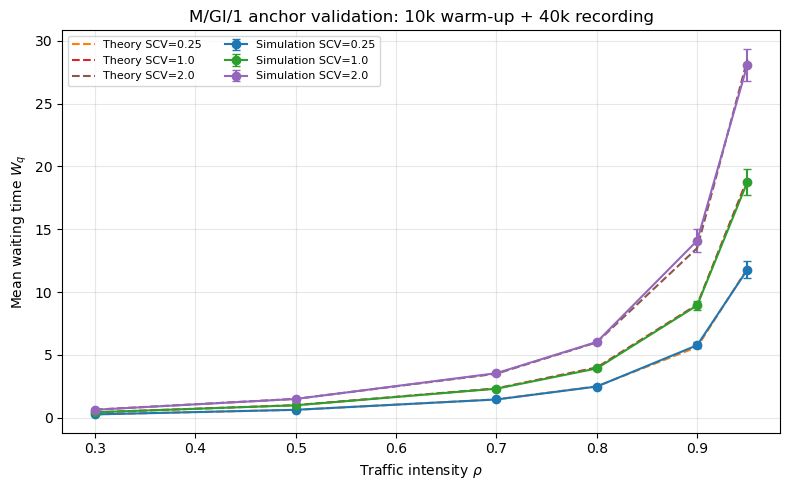

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))

for scv in ANCHOR_SCVS:
    tmp = anchor_labels[
        np.isclose(anchor_labels["service_scv"], scv)
    ].sort_values("rho")

    yerr = np.vstack([
        tmp["Wq_sim_mean"] - tmp["Wq_ci95_low"],
        tmp["Wq_ci95_high"] - tmp["Wq_sim_mean"],
    ])

    ax.errorbar(
        tmp["rho"],
        tmp["Wq_sim_mean"],
        yerr=yerr,
        marker="o",
        capsize=3,
        label=f"Simulation SCV={scv}",
    )
    ax.plot(
        tmp["rho"],
        tmp["Wq_theory"],
        linestyle="--",
        label=f"Theory SCV={scv}",
    )

ax.set_xlabel(r"Traffic intensity $\rho$")
ax.set_ylabel(r"Mean waiting time $W_q$")
ax.set_title("M/GI/1 anchor validation: 10k warm-up + 40k recording")
ax.grid(alpha=0.3)
ax.legend(ncol=2, fontsize=8)
fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "mgi1_anchor18_validation_Wq_10k40k.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


## 7. Initial configuration-level ML dataset design

The first stationary ML dataset uses 20 utilisation values between 0.30 and 0.95 and 10 service-time SCV values between 0.25 and 2.0, giving 200 distinct configurations. The grid deliberately retains the original validation anchors $\rho\in\{0.3,0.5,0.7,0.8,0.9,0.95\}$ and $\mathrm{SCV}\in\{0.25,1,2\}$.

The configuration is the unit of learning and splitting. **All replications belonging to one configuration stay together.** The current design uses a 70/15/15 train/validation/test allocation with coarse stratification so that low/moderate/high regions remain represented across partitions. The final test configurations are not used for fitting or hyperparameter selection.

Because $E[S]=1$, $\lambda=\rho$. `lambda_rate` is stored as metadata, but the initial ML inputs remain only the raw system descriptors $(\rho,\mathrm{SCV}_S)$ to avoid duplicating exactly equivalent information.

The size of this grid is not assumed to be final. If validation behaviour indicates that 200 configurations provide insufficient coverage for stable flexible-model performance, the same construction can be expanded to 300--400 configurations without changing the simulation or ML logic.


In [10]:
# 20 rho values with the original six validation levels retained.
RHO_GRID = np.array([
    0.30, 0.34, 0.37, 0.40, 0.44,
    0.47, 0.50, 0.54, 0.57, 0.60,
    0.64, 0.67, 0.70, 0.74, 0.77,
    0.80, 0.84, 0.87, 0.90, 0.95,
])

# 10 SCV values with 0.25, 1.0 and 2.0 retained as anchors.
SCV_GRID = np.array([
    0.25, 0.45, 0.65, 0.85, 1.00,
    1.15, 1.35, 1.55, 1.75, 2.00,
])

configuration_design = (
    pd.MultiIndex.from_product(
        [RHO_GRID, SCV_GRID],
        names=["rho", "service_scv"],
    )
    .to_frame(index=False)
)

configuration_design.insert(
    0,
    "config_id",
    [f"cfg_{i:03d}" for i in range(len(configuration_design))],
)
configuration_design["service_mean"] = SERVICE_MEAN
configuration_design["lambda_rate"] = (
    configuration_design["rho"] / SERVICE_MEAN
)
configuration_design["warmup_time"] = SIM_WARMUP_TIME
configuration_design["record_time"] = SIM_RECORD_TIME
configuration_design["dt"] = DT

# Exact theoretical benchmark for every configuration.
theory_rows = []
for _, row in configuration_design.iterrows():
    theory_rows.append(
        mgi1_theory(
            rho=float(row["rho"]),
            service_scv=float(row["service_scv"]),
            service_mean=SERVICE_MEAN,
        )
    )
theory_df = pd.DataFrame(theory_rows)
configuration_design["Wq_theory"] = theory_df["Wq_theory"].to_numpy()
configuration_design["Lq_theory"] = theory_df["Lq_theory"].to_numpy()

configuration_design["is_anchor"] = (
    configuration_design["rho"].isin(ANCHOR_RHOS)
    & configuration_design["service_scv"].isin(ANCHOR_SCVS)
)

# Coarse strata used only for reproducible coverage in the configuration split.
configuration_design["rho_band"] = pd.cut(
    configuration_design["rho"],
    bins=[0.299, 0.50, 0.70, 0.85, 0.951],
    labels=["low", "moderate", "high", "very_high"],
    include_lowest=True,
)
configuration_design["scv_band"] = pd.cut(
    configuration_design["service_scv"],
    bins=[0.249, 0.80, 1.40, 2.001],
    labels=["low", "moderate", "high"],
    include_lowest=True,
)
configuration_design["stratum"] = (
    configuration_design["rho_band"].astype(str)
    + "_"
    + configuration_design["scv_band"].astype(str)
)

# Split configurations, never replications.
N_CONFIGURATIONS = len(configuration_design)
N_TEST = int(round(TEST_FRACTION * N_CONFIGURATIONS))
N_VALIDATION = int(round(VALIDATION_FRACTION * N_CONFIGURATIONS))
N_TRAIN = N_CONFIGURATIONS - N_TEST - N_VALIDATION

train_val, test = train_test_split(
    configuration_design,
    test_size=N_TEST,
    random_state=BASE_SEED,
    stratify=configuration_design["stratum"],
)
train, validation = train_test_split(
    train_val,
    test_size=N_VALIDATION,
    random_state=BASE_SEED + 1,
    stratify=train_val["stratum"],
)

configuration_design["split"] = ""
configuration_design.loc[
    configuration_design["config_id"].isin(train["config_id"]), "split"
] = "train"
configuration_design.loc[
    configuration_design["config_id"].isin(validation["config_id"]), "split"
] = "validation"
configuration_design.loc[
    configuration_design["config_id"].isin(test["config_id"]), "split"
] = "test"

split_counts = configuration_design["split"].value_counts()
assert split_counts["train"] == N_TRAIN
assert split_counts["validation"] == N_VALIDATION
assert split_counts["test"] == N_TEST

configuration_design.to_csv(
    OUTPUT_DIR / f"mgi1_configuration_design_{N_CONFIGURATIONS}.csv",
    index=False,
)

print(configuration_design["split"].value_counts())
print(f"Anchor configurations retained: {configuration_design['is_anchor'].sum()}")
display(configuration_design.head(12))


split
train         140
test           30
validation     30
Name: count, dtype: int64
Anchor configurations retained: 18


,config_id,rho,service_scv,service_mean,lambda_rate,warmup_time,record_time,dt,Wq_theory,Lq_theory,is_anchor,rho_band,scv_band,stratum,split
0,cfg_000,0.30,0.25,1.0,0.30,10000.0,40000.0,1.0,0.267857,0.080357,True,low,low,low_low,train
1,cfg_001,0.30,0.45,1.0,0.30,10000.0,40000.0,1.0,0.310714,0.093214,False,low,low,low_low,train
2,cfg_002,0.30,0.65,1.0,0.30,10000.0,40000.0,1.0,0.353571,0.106071,False,low,low,low_low,train
3,cfg_003,0.30,0.85,1.0,0.30,10000.0,40000.0,1.0,0.396429,0.118929,False,low,moderate,low_moderate,train
4,cfg_004,0.30,1.00,1.0,0.30,10000.0,40000.0,1.0,0.428571,0.128571,True,low,moderate,low_moderate,test
5,cfg_005,0.30,1.15,1.0,0.30,10000.0,40000.0,1.0,0.460714,0.138214,False,low,moderate,low_moderate,train
6,cfg_006,0.30,1.35,1.0,0.30,10000.0,40000.0,1.0,0.503571,0.151071,False,low,moderate,low_moderate,train
7,cfg_007,0.30,1.55,1.0,0.30,10000.0,40000.0,1.0,0.546429,0.163929,False,low,high,low_high,train
8,cfg_008,0.30,1.75,1.0,0.30,10000.0,40000.0,1.0,0.589286,0.176786,False,low,high,low_high,test
9,cfg_009,0.30,2.00,1.0,0.30,10000.0,40000.0,1.0,0.642857,0.192857,True,low,high,low_high,train


### 7.1 Design coverage check


In [11]:
coverage = pd.crosstab(
    [configuration_design["rho_band"], configuration_design["scv_band"]],
    configuration_design["split"],
    dropna=False,
)
coverage.to_csv(OUTPUT_DIR / "mgi1_configuration_split_coverage.csv")
display(coverage)


split               test  train  validation
rho_band  scv_band                         
low       low          3     15           3
          moderate     4     20           4
          high         3     15           3
moderate  low          3     12           3
          moderate     4     16           4
          high         3     12           3
high      low          2      8           2
          moderate     2     12           2
          high         2      8           2
very_high low          1      7           1
          moderate     2      8           2
          high         1      7           1

## 8. Simulation-cost benchmark

The current 200-configuration design requires

$$
200\times30=6000
$$

independent simulation replications. The reliability-pilot runtimes are retained as a machine-specific benchmark for the computational cost of the candidate simulation horizons. The final production design uses the 10,000 + 40,000 setting; actual full-dataset wall time is recorded separately during label generation.


In [12]:
total_runs = len(configuration_design) * N_REPLICATIONS

cost_rows = []
for design_name, (warm, record) in PILOT_DESIGNS.items():
    times = pilot_replications.loc[
        pilot_replications["pilot_design"] == design_name,
        "runtime_seconds",
    ]

    mean_seconds = float(times.mean())
    median_seconds = float(times.median())

    cost_rows.append({
        "candidate_design": design_name,
        "warmup_time": warm,
        "record_time": record,
        "n_configurations": len(configuration_design),
        "replications_per_configuration": N_REPLICATIONS,
        "total_simulation_runs": total_runs,
        "mean_seconds_per_rep_from_pilot": mean_seconds,
        "median_seconds_per_rep_from_pilot": median_seconds,
        "estimated_full_seconds": mean_seconds * total_runs,
        "estimated_full_minutes": mean_seconds * total_runs / 60.0,
    })

cost_estimate = pd.DataFrame(cost_rows)

cost_estimate.to_csv(
    OUTPUT_DIR / "mgi1_simulation_cost_benchmark.csv",
    index=False,
)

display(cost_estimate.round(4))


,candidate_design,warmup_time,record_time,n_configurations,replications_per_configuration,total_simulation_runs,mean_seconds_per_rep_from_pilot,median_seconds_per_rep_from_pilot,estimated_full_seconds,estimated_full_minutes
0,baseline,10000.0,20000.0,200,30,6000,0.0006,0.0005,3.3894,0.0565
1,longer_warmup,20000.0,20000.0,200,30,6000,0.0007,0.0007,4.4321,0.0739
2,longer_recording,10000.0,40000.0,200,30,6000,0.0009,0.0009,5.5711,0.0929


## 9. Full configuration-level stationary dataset

The confirmed production design uses **10,000 warm-up + 40,000 recording time units** and 30 independent replications for every configuration. Each configuration is aggregated to one stationary label, `Wq_sim_mean`, with replication-level uncertainty stored alongside it.

The exact Pollaczek--Khinchine value is retained only as an external benchmark. It is not used to construct the training label.


In [13]:
def generate_full_replication_dataset(
    design_df,
    replications=N_REPLICATIONS,
    warmup_time=SIM_WARMUP_TIME,
    record_time=SIM_RECORD_TIME,
):
    frames = []
    start_all = time.perf_counter()

    for j, (_, cfg) in enumerate(design_df.iterrows(), start=1):
        if j == 1 or j % 10 == 0 or j == len(design_df):
            print(
                f"[{j}/{len(design_df)}] {cfg['config_id']} "
                f"rho={cfg['rho']:.2f}, SCV={cfg['service_scv']:.2f}"
            )

        frames.append(
            run_replications_for_config(
                config_id=cfg["config_id"],
                rho=float(cfg["rho"]),
                service_scv=float(cfg["service_scv"]),
                replications=replications,
                warmup_time=warmup_time,
                record_time=record_time,
                seed_offset=40_000_000,
            )
        )

    full_replications = pd.concat(frames, ignore_index=True)
    full_replications = (
        full_replications
        .sort_values(["config_id", "replication"])
        .drop_duplicates(["config_id", "replication"], keep="first")
        .reset_index(drop=True)
    )

    runtime_total = time.perf_counter() - start_all
    return full_replications, runtime_total


full_replications, full_simulation_runtime_seconds = (
    generate_full_replication_dataset(
        design_df=configuration_design,
        warmup_time=SIM_WARMUP_TIME,
        record_time=SIM_RECORD_TIME,
    )
)

full_replications.to_csv(
    OUTPUT_DIR / f"mgi1_full_{N_CONFIGURATIONS}_replications.csv",
    index=False,
)

stationary_labels = aggregate_configuration_labels(full_replications)
stationary_labels = stationary_labels.merge(
    configuration_design[["config_id", "split"]],
    on="config_id",
    how="left",
    validate="one_to_one",
)

assert len(stationary_labels) == len(configuration_design)
assert stationary_labels["config_id"].is_unique

stationary_labels.to_csv(
    OUTPUT_DIR / f"mgi1_stationary_{N_CONFIGURATIONS}_labels.csv",
    index=False,
)

print(
    f"Full label generation completed in "
    f"{full_simulation_runtime_seconds/60:.2f} minutes."
)
display(stationary_labels.head())


[1/200] cfg_000 rho=0.30, SCV=0.25
[10/200] cfg_009 rho=0.30, SCV=2.00
[20/200] cfg_019 rho=0.34, SCV=2.00
[30/200] cfg_029 rho=0.37, SCV=2.00
[40/200] cfg_039 rho=0.40, SCV=2.00
[50/200] cfg_049 rho=0.44, SCV=2.00
[60/200] cfg_059 rho=0.47, SCV=2.00
[70/200] cfg_069 rho=0.50, SCV=2.00
[80/200] cfg_079 rho=0.54, SCV=2.00
[90/200] cfg_089 rho=0.57, SCV=2.00
[100/200] cfg_099 rho=0.60, SCV=2.00
[110/200] cfg_109 rho=0.64, SCV=2.00
[120/200] cfg_119 rho=0.67, SCV=2.00
[130/200] cfg_129 rho=0.70, SCV=2.00
[140/200] cfg_139 rho=0.74, SCV=2.00
[150/200] cfg_149 rho=0.77, SCV=2.00
[160/200] cfg_159 rho=0.80, SCV=2.00
[170/200] cfg_169 rho=0.84, SCV=2.00
[180/200] cfg_179 rho=0.87, SCV=2.00
[190/200] cfg_189 rho=0.90, SCV=2.00
[200/200] cfg_199 rho=0.95, SCV=2.00
Full label generation completed in 0.10 minutes.


,config_id,rho,lambda_rate,service_mean,service_scv,warmup_time,record_time,n_replications,Wq_theory,Wq_sim_mean,...,Wq_rel_error_vs_theory_pct,Lq_theory,Lq_sim_from_Wq,Lq_ci95_low_from_Wq,Lq_ci95_high_from_Wq,lambda_hat_mean,service_mean_hat_mean,service_scv_hat_mean,mean_runtime_seconds_per_rep,split
0,cfg_000,0.3,0.3,1.0,0.25,10000.0,40000.0,30,0.267857,0.267842,...,0.005661,0.080357,0.080353,0.079148,0.081557,0.300897,1.001426,0.249455,0.000464,train
1,cfg_001,0.3,0.3,1.0,0.45,10000.0,40000.0,30,0.310714,0.307995,...,0.875163,0.093214,0.092399,0.091119,0.093678,0.299385,1.000169,0.450037,0.000465,train
2,cfg_002,0.3,0.3,1.0,0.65,10000.0,40000.0,30,0.353571,0.353568,...,0.000925,0.106071,0.106070,0.104358,0.107783,0.299361,1.002462,0.651276,0.000403,train
3,cfg_003,0.3,0.3,1.0,0.85,10000.0,40000.0,30,0.396429,0.396730,...,0.075938,0.118929,0.119019,0.117361,0.120676,0.299544,0.998634,0.852876,0.000411,train
4,cfg_004,0.3,0.3,1.0,1.00,10000.0,40000.0,30,0.428571,0.431133,...,0.597807,0.128571,0.129340,0.127601,0.131079,0.299710,1.001579,0.999963,0.000342,test


## 10. Stationary ML experiment — common configuration split

### Prediction target

$$
(\rho,\mathrm{SCV}_S)\rightarrow \widehat W_q.
$$

The simulation-estimated configuration mean `Wq_sim_mean` is the training label. The exact Pollaczek--Khinchine `Wq_theory` is **not used for training or hyperparameter selection**; it is reserved for final evaluation.

### Inputs

All models initially use the same raw system inputs

$$
(\rho,\mathrm{SCV}_S).
$$

No queueing-informed transformations are added to the Linear Regression baseline in this experiment.

### Models and evaluation discipline

- Linear Regression: raw-input baseline;
- Decision Tree: single nonlinear tree;
- Random Forest: bagging-based tree ensemble;
- XGBoost: boosted tree ensemble.

Tree-model settings are selected using the validation configurations only. Every model is finally evaluated on the **same held-out test configurations**. Absolute and relative errors are reported against the exact PK mean, while comparisons with the simulation mean label are also retained to separate model error from label noise. Small differences between flexible models are interpreted cautiously rather than treated as definitive rankings.


In [14]:
def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))


def regression_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    abs_error = np.abs(y_pred - y_true)
    rel_error_pct = 100.0 * abs_error / np.abs(y_true)

    return {
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "RMSE": rmse(y_true, y_pred),
        "R2": float(r2_score(y_true, y_pred)),
        "MAPE_pct": float(rel_error_pct.mean()),
        "Median_APE_pct": float(np.median(rel_error_pct)),
    }


def average_prediction_time(model, X, repeats=500):
    # Test sets are small; repeated calls reduce timer noise.
    start = time.perf_counter()
    for _ in range(repeats):
        model.predict(X)
    elapsed = time.perf_counter() - start
    return elapsed / repeats


### 10.1 Linear Regression baseline and XGBoost validation search


In [15]:
model_metrics = None
stationary_test_predictions = None
chosen_xgb_params = None
model_timing = None

labels_path = OUTPUT_DIR / f"mgi1_stationary_{N_CONFIGURATIONS}_labels.csv"

labels = pd.read_csv(labels_path)
if len(labels) != N_CONFIGURATIONS:
    raise ValueError(
        f"Expected {N_CONFIGURATIONS} configuration-level rows, got {len(labels)}."
    )

feature_cols = ["rho", "service_scv"]
target_col = "Wq_sim_mean"

train_df = labels[labels["split"] == "train"].copy()
val_df = labels[labels["split"] == "validation"].copy()
test_df = labels[labels["split"] == "test"].copy()

assert len(train_df) == N_TRAIN
assert len(val_df) == N_VALIDATION
assert len(test_df) == N_TEST

X_train = train_df[feature_cols]
y_train = train_df[target_col]
X_val = val_df[feature_cols]
y_val = val_df[target_col]
X_test = test_df[feature_cols]

# -----------------------------
# Raw-input Linear Regression
# -----------------------------
lr_for_val = LinearRegression()
start = time.perf_counter()
lr_for_val.fit(X_train, y_train)
lr_val_train_seconds = time.perf_counter() - start
lr_val_pred = lr_for_val.predict(X_val)
lr_val_rmse = rmse(y_val, lr_val_pred)

# -----------------------------
# Modest XGBoost validation search
# -----------------------------
xgb_candidates = [
    {"n_estimators": 150, "max_depth": 2, "learning_rate": 0.03},
    {"n_estimators": 250, "max_depth": 2, "learning_rate": 0.03},
    {"n_estimators": 150, "max_depth": 2, "learning_rate": 0.05},
    {"n_estimators": 250, "max_depth": 2, "learning_rate": 0.05},
    {"n_estimators": 150, "max_depth": 3, "learning_rate": 0.03},
    {"n_estimators": 250, "max_depth": 3, "learning_rate": 0.03},
    {"n_estimators": 150, "max_depth": 3, "learning_rate": 0.05},
    {"n_estimators": 250, "max_depth": 3, "learning_rate": 0.05},
]

tuning_rows = []
for params in xgb_candidates:
    model = XGBRegressor(
        objective="reg:squarederror",
        random_state=BASE_SEED,
        n_jobs=-1,
        subsample=1.0,
        colsample_bytree=1.0,
        **params,
    )

    start = time.perf_counter()
    model.fit(X_train, y_train)
    train_seconds = time.perf_counter() - start
    pred = model.predict(X_val)

    tuning_rows.append({
        **params,
        "validation_RMSE_vs_sim_label": rmse(y_val, pred),
        "training_seconds": train_seconds,
    })

tuning_results = (
    pd.DataFrame(tuning_rows)
    .sort_values("validation_RMSE_vs_sim_label")
    .reset_index(drop=True)
)
tuning_results.to_csv(
    OUTPUT_DIR / "mgi1_xgb_validation_search.csv",
    index=False,
)

chosen_xgb_params = {
    "n_estimators": int(tuning_results.loc[0, "n_estimators"]),
    "max_depth": int(tuning_results.loc[0, "max_depth"]),
    "learning_rate": float(tuning_results.loc[0, "learning_rate"]),
}

with open(OUTPUT_DIR / "mgi1_xgb_chosen_settings.json", "w") as f:
    json.dump(chosen_xgb_params, f, indent=2)

print("Linear Regression validation RMSE:", round(lr_val_rmse, 6))
print("Chosen XGBoost settings:", chosen_xgb_params)
display(tuning_results)

# -----------------------------
# Refit final models on train + validation configurations
# -----------------------------
trainval_df = pd.concat([train_df, val_df], ignore_index=True)
X_trainval = trainval_df[feature_cols]
y_trainval = trainval_df[target_col]

final_lr = LinearRegression()
start = time.perf_counter()
final_lr.fit(X_trainval, y_trainval)
lr_final_train_seconds = time.perf_counter() - start

final_xgb = XGBRegressor(
    objective="reg:squarederror",
    random_state=BASE_SEED,
    n_jobs=-1,
    subsample=1.0,
    colsample_bytree=1.0,
    **chosen_xgb_params,
)
start = time.perf_counter()
final_xgb.fit(X_trainval, y_trainval)
xgb_final_train_seconds = time.perf_counter() - start

lr_pred = final_lr.predict(X_test)
xgb_pred = final_xgb.predict(X_test)

# Final evaluation against exact theory (primary reference)
y_theory = test_df["Wq_theory"].to_numpy()
y_sim = test_df["Wq_sim_mean"].to_numpy()

metric_rows = []
for model_name, pred in [
    ("Linear Regression (raw)", lr_pred),
    ("XGBoost", xgb_pred),
]:
    metric_rows.append({
        "Model": model_name,
        "Reference": "PK theory",
        **regression_metrics(y_theory, pred),
    })
    metric_rows.append({
        "Model": model_name,
        "Reference": "simulation mean label",
        **regression_metrics(y_sim, pred),
    })

model_metrics = pd.DataFrame(metric_rows)
model_metrics.to_csv(
    OUTPUT_DIR / "mgi1_stationary_test_metrics.csv",
    index=False,
)

# Configuration-level final predictions and errors
stationary_test_predictions = test_df[[
    "config_id", "rho", "lambda_rate", "service_scv",
    "Wq_theory", "Wq_sim_mean", "Wq_ci95_low", "Wq_ci95_high",
    "Lq_theory", "Lq_sim_from_Wq",
]].copy()

stationary_test_predictions["Wq_pred_LR"] = lr_pred
stationary_test_predictions["Wq_pred_XGB"] = xgb_pred
stationary_test_predictions["Lq_pred_LR"] = (
    stationary_test_predictions["lambda_rate"] * lr_pred
)
stationary_test_predictions["Lq_pred_XGB"] = (
    stationary_test_predictions["lambda_rate"] * xgb_pred
)

for short in ["LR", "XGB"]:
    stationary_test_predictions[f"Wq_abs_error_{short}_vs_theory"] = (
        stationary_test_predictions[f"Wq_pred_{short}"]
        - stationary_test_predictions["Wq_theory"]
    ).abs()
    stationary_test_predictions[f"Wq_rel_error_pct_{short}_vs_theory"] = (
        100.0
        * stationary_test_predictions[f"Wq_abs_error_{short}_vs_theory"]
        / stationary_test_predictions["Wq_theory"].abs()
    )

stationary_test_predictions["Wq_sim_rel_error_pct_vs_theory"] = (
    100.0
    * (stationary_test_predictions["Wq_sim_mean"]
       - stationary_test_predictions["Wq_theory"]).abs()
    / stationary_test_predictions["Wq_theory"].abs()
)

stationary_test_predictions.to_csv(
    OUTPUT_DIR / "mgi1_stationary_test_predictions.csv",
    index=False,
)

# Timing kept separate by task.
model_timing = pd.DataFrame([
    {
        "stage": "simulation_label_generation",
        "seconds": (
            full_simulation_runtime_seconds
            if full_simulation_runtime_seconds is not None
            else np.nan
        ),
        "note": "wall time for missing full-dataset simulations in this session",
    },
    {
        "stage": "linear_regression_training",
        "seconds": lr_final_train_seconds,
        "note": f"fit on {len(trainval_df)} train+validation configurations",
    },
    {
        "stage": "xgboost_training",
        "seconds": xgb_final_train_seconds,
        "note": f"final fit on {len(trainval_df)} train+validation configurations",
    },
    {
        "stage": "linear_regression_prediction",
        "seconds": average_prediction_time(final_lr, X_test),
        "note": f"average time to predict all {len(test_df)} held-out configurations",
    },
    {
        "stage": "xgboost_prediction",
        "seconds": average_prediction_time(final_xgb, X_test),
        "note": f"average time to predict all {len(test_df)} held-out configurations",
    },
])
model_timing.to_csv(
    OUTPUT_DIR / "mgi1_timing_summary.csv",
    index=False,
)

# LR/XGBoost results are retained for the final four-model comparison below.

Linear Regression validation RMSE: 2.456282
Chosen XGBoost settings: {'n_estimators': 250, 'max_depth': 3, 'learning_rate': 0.03}


,n_estimators,max_depth,learning_rate,validation_RMSE_vs_sim_label,training_seconds
0,250,3,0.03,0.328209,0.027585
1,250,3,0.05,0.362486,0.025212
2,150,3,0.05,0.372445,0.017995
3,150,3,0.03,0.376744,0.018466
4,250,2,0.05,0.397592,0.023309
5,250,2,0.03,0.405589,0.021684
6,150,2,0.05,0.406935,0.012533
7,150,2,0.03,0.471574,0.027434


### 10.2 Simulation uncertainty shown separately from ML prediction error


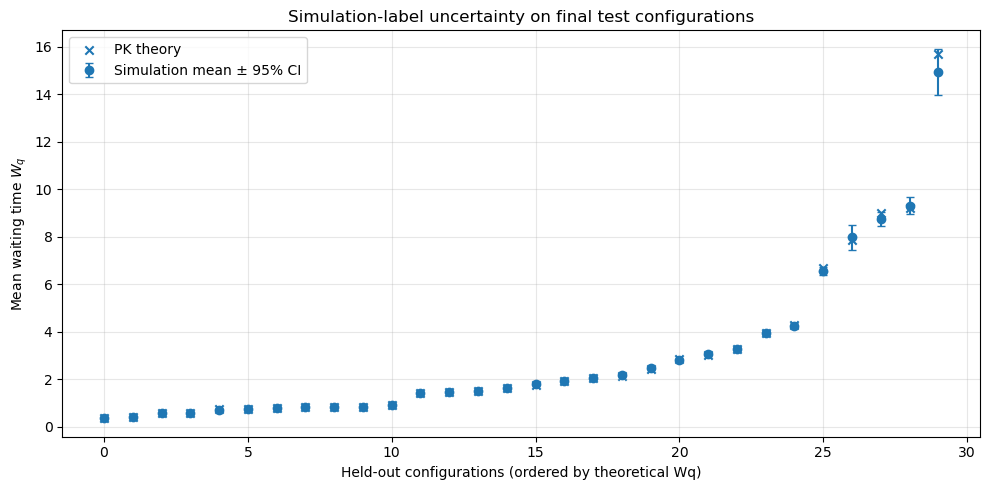

In [16]:
plot_df = stationary_test_predictions.sort_values("Wq_theory").reset_index(drop=True)
x = np.arange(len(plot_df))
yerr = np.vstack([
    plot_df["Wq_sim_mean"] - plot_df["Wq_ci95_low"],
    plot_df["Wq_ci95_high"] - plot_df["Wq_sim_mean"],
])

fig, ax = plt.subplots(figsize=(10, 5))
ax.errorbar(
    x,
    plot_df["Wq_sim_mean"],
    yerr=yerr,
    fmt="o",
    capsize=3,
    label="Simulation mean ± 95% CI",
)
ax.scatter(x, plot_df["Wq_theory"], marker="x", label="PK theory")
ax.set_xlabel("Held-out configurations (ordered by theoretical Wq)")
ax.set_ylabel(r"Mean waiting time $W_q$")
ax.set_title("Simulation-label uncertainty on final test configurations")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "mgi1_test_simulation_uncertainty.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


## 11. Full tree-based model comparison

Decision Tree and Random Forest are added to the existing Linear Regression and XGBoost experiment. The inputs, target, train/validation/test configuration split, and held-out test configurations are unchanged, so all four models are compared on exactly the same evaluation cases.


### 11.1 Decision Tree and Random Forest validation search


In [17]:
# ============================================================
# 11.1 Tune Decision Tree and Random Forest on validation set
# ============================================================

expanded_model_metrics = None
expanded_test_predictions = None

chosen_dt_params = None
chosen_rf_params = None



# --------------------------------------------------------
# Reuse exactly the same train / validation / test split
# already created in Section 10
# --------------------------------------------------------

# ========================================================
# Decision Tree
# ========================================================

dt_candidates = [
    {"max_depth": 2, "min_samples_leaf": 1},
    {"max_depth": 3, "min_samples_leaf": 1},
    {"max_depth": 4, "min_samples_leaf": 1},
    {"max_depth": 5, "min_samples_leaf": 1},
    {"max_depth": 3, "min_samples_leaf": 2},
    {"max_depth": 4, "min_samples_leaf": 2},
    {"max_depth": 5, "min_samples_leaf": 2},
    {"max_depth": None, "min_samples_leaf": 2},
]

dt_tuning_rows = []

for params in dt_candidates:

    model = DecisionTreeRegressor(
        random_state=BASE_SEED,
        **params,
    )

    start = time.perf_counter()
    model.fit(X_train, y_train)
    training_seconds = time.perf_counter() - start

    pred = model.predict(X_val)

    dt_tuning_rows.append({
        **params,
        "validation_RMSE_vs_sim_label": rmse(y_val, pred),
        "training_seconds": training_seconds,
    })


dt_tuning_results = (
    pd.DataFrame(dt_tuning_rows)
    .sort_values("validation_RMSE_vs_sim_label")
    .reset_index(drop=True)
)

dt_tuning_results.to_csv(
    OUTPUT_DIR / "mgi1_dt_validation_search.csv",
    index=False,
)


best_dt_row = dt_tuning_results.iloc[0]

chosen_dt_params = {
    "max_depth": (
        None
        if pd.isna(best_dt_row["max_depth"])
        else int(best_dt_row["max_depth"])
    ),
    "min_samples_leaf": int(
        best_dt_row["min_samples_leaf"]
    ),
}


# ========================================================
# Random Forest
# ========================================================

rf_candidates = [
    {
        "n_estimators": 300,
        "max_depth": 3,
        "min_samples_leaf": 1,
    },
    {
        "n_estimators": 300,
        "max_depth": 3,
        "min_samples_leaf": 2,
    },
    {
        "n_estimators": 300,
        "max_depth": 5,
        "min_samples_leaf": 1,
    },
    {
        "n_estimators": 300,
        "max_depth": 5,
        "min_samples_leaf": 2,
    },
    {
        "n_estimators": 300,
        "max_depth": None,
        "min_samples_leaf": 1,
    },
    {
        "n_estimators": 300,
        "max_depth": None,
        "min_samples_leaf": 2,
    },
]

rf_tuning_rows = []

for params in rf_candidates:

    model = RandomForestRegressor(
        random_state=BASE_SEED,
        n_jobs=-1,
        **params,
    )

    start = time.perf_counter()
    model.fit(X_train, y_train)
    training_seconds = time.perf_counter() - start

    pred = model.predict(X_val)

    rf_tuning_rows.append({
        **params,
        "validation_RMSE_vs_sim_label": rmse(y_val, pred),
        "training_seconds": training_seconds,
    })


rf_tuning_results = (
    pd.DataFrame(rf_tuning_rows)
    .sort_values("validation_RMSE_vs_sim_label")
    .reset_index(drop=True)
)

rf_tuning_results.to_csv(
    OUTPUT_DIR / "mgi1_rf_validation_search.csv",
    index=False,
)


best_rf_row = rf_tuning_results.iloc[0]

chosen_rf_params = {
    "n_estimators": int(
        best_rf_row["n_estimators"]
    ),
    "max_depth": (
        None
        if pd.isna(best_rf_row["max_depth"])
        else int(best_rf_row["max_depth"])
    ),
    "min_samples_leaf": int(
        best_rf_row["min_samples_leaf"]
    ),
}


print("Chosen Decision Tree settings:")
print(chosen_dt_params)

print("\nDecision Tree validation results:")
display(dt_tuning_results.round(6))


print("\nChosen Random Forest settings:")
print(chosen_rf_params)

print("\nRandom Forest validation results:")
display(rf_tuning_results.round(6))


Chosen Decision Tree settings:
{'max_depth': 5, 'min_samples_leaf': 1}

Decision Tree validation results:


,max_depth,min_samples_leaf,validation_RMSE_vs_sim_label,training_seconds
0,5.0,1,0.881741,0.000486
1,4.0,1,1.089774,0.000434
2,3.0,1,1.221678,0.000473
3,NaN,2,1.335142,0.000427
4,5.0,2,1.376497,0.000338
5,4.0,2,1.463244,0.000355
6,3.0,2,1.497289,0.000427
7,2.0,1,1.982537,0.000777



Chosen Random Forest settings:
{'n_estimators': 300, 'max_depth': None, 'min_samples_leaf': 1}

Random Forest validation results:


,n_estimators,max_depth,min_samples_leaf,validation_RMSE_vs_sim_label,training_seconds
0,300,NaN,1,1.001872,0.098293
1,300,5.0,1,1.042898,0.099719
2,300,3.0,1,1.322449,0.110452
3,300,NaN,2,1.389818,0.106546
4,300,5.0,2,1.403079,0.096429
5,300,3.0,2,1.586737,0.094328


### 11.2 Held-out test comparison for all four models


In [18]:

# ========================================================
# Refit DT and RF on train + validation configurations
# ========================================================

final_dt = DecisionTreeRegressor(
    random_state=BASE_SEED,
    **chosen_dt_params,
)

start = time.perf_counter()
final_dt.fit(X_trainval, y_trainval)
dt_final_train_seconds = time.perf_counter() - start


final_rf = RandomForestRegressor(
    random_state=BASE_SEED,
    n_jobs=-1,
    **chosen_rf_params,
)

start = time.perf_counter()
final_rf.fit(X_trainval, y_trainval)
rf_final_train_seconds = time.perf_counter() - start


# ========================================================
# Predictions on exactly the same held-out test set
# ========================================================

dt_pred = final_dt.predict(X_test)
rf_pred = final_rf.predict(X_test)


# ========================================================
# Metrics for the two newly added models
# ========================================================

additional_metric_rows = []

for model_name, pred in [
    ("Decision Tree", dt_pred),
    ("Random Forest", rf_pred),
]:

    additional_metric_rows.append({
        "Model": model_name,
        "Reference": "PK theory",
        **regression_metrics(y_theory, pred),
    })

    additional_metric_rows.append({
        "Model": model_name,
        "Reference": "simulation mean label",
        **regression_metrics(y_sim, pred),
    })


additional_model_metrics = pd.DataFrame(
    additional_metric_rows
)


# ========================================================
# Combine with original Section 10 results
# ========================================================

expanded_model_metrics = pd.concat(
    [
        model_metrics,
        additional_model_metrics,
    ],
    ignore_index=True,
)


expanded_model_metrics.to_csv(
    OUTPUT_DIR
    / "mgi1_expanded_model_test_metrics.csv",
    index=False,
)


print(
    "Expanded model comparison "
    "(same held-out test configurations):"
)

display(
    expanded_model_metrics.round(5)
)

# Add DT/RF timing to the same timing table; keep simulation, training, and prediction separate.
model_timing = pd.concat([
    model_timing,
    pd.DataFrame([
        {
            "stage": "decision_tree_training",
            "seconds": dt_final_train_seconds,
            "note": f"final fit on {len(trainval_df)} train+validation configurations",
        },
        {
            "stage": "random_forest_training",
            "seconds": rf_final_train_seconds,
            "note": f"final fit on {len(trainval_df)} train+validation configurations",
        },
        {
            "stage": "decision_tree_prediction",
            "seconds": average_prediction_time(final_dt, X_test, repeats=50),
            "note": f"average time to predict all {len(test_df)} held-out configurations",
        },
        {
            "stage": "random_forest_prediction",
            "seconds": average_prediction_time(final_rf, X_test, repeats=50),
            "note": f"average time to predict all {len(test_df)} held-out configurations",
        },
    ])
], ignore_index=True)

model_timing.to_csv(
    OUTPUT_DIR / "mgi1_timing_summary.csv",
    index=False,
)


Expanded model comparison (same held-out test configurations):


,Model,Reference,MAE,RMSE,R2,MAPE_pct,Median_APE_pct
0,Linear Regression (raw),PK theory,1.74969,2.21744,0.57533,124.04279,89.12278
1,Linear Regression (raw),simulation mean label,1.71844,2.13630,0.58219,123.52148,89.46407
2,XGBoost,PK theory,0.17408,0.35288,0.98925,6.48473,4.53223
3,XGBoost,simulation mean label,0.20981,0.48796,0.97820,6.87734,4.75271
4,Decision Tree,PK theory,0.51362,0.70266,0.95736,24.21725,21.02599
5,Decision Tree,simulation mean label,0.48384,0.63511,0.96307,24.07245,21.27996
6,Random Forest,PK theory,0.15131,0.25549,0.99436,5.32086,3.48654
7,Random Forest,simulation mean label,0.13836,0.23256,0.99505,5.32195,3.02698


In [19]:
## generate expanded predictions

# Start from the Section 10 test prediction table
expanded_test_predictions = (
    stationary_test_predictions.copy()
)

# Add the two new model predictions
expanded_test_predictions[
    "Wq_pred_DT"
] = dt_pred

expanded_test_predictions[
    "Wq_pred_RF"
] = rf_pred


# Corresponding mean queue-length predictions
expanded_test_predictions[
    "Lq_pred_DT"
] = (
    expanded_test_predictions["lambda_rate"]
    * dt_pred
)

expanded_test_predictions[
    "Lq_pred_RF"
] = (
    expanded_test_predictions["lambda_rate"]
    * rf_pred
)


# Errors relative to exact PK theory
for short in ["DT", "RF"]:

    expanded_test_predictions[
        f"Wq_abs_error_{short}_vs_theory"
    ] = (
        expanded_test_predictions[
            f"Wq_pred_{short}"
        ]
        - expanded_test_predictions["Wq_theory"]
    ).abs()

    expanded_test_predictions[
        f"Wq_rel_error_pct_{short}_vs_theory"
    ] = (
        100.0
        * expanded_test_predictions[
            f"Wq_abs_error_{short}_vs_theory"
        ]
        / expanded_test_predictions[
            "Wq_theory"
        ].abs()
    )


expanded_test_predictions.to_csv(
    OUTPUT_DIR
    / "mgi1_expanded_test_predictions.csv",
    index=False,
)
display(expanded_test_predictions.head(5))


,config_id,rho,lambda_rate,service_scv,Wq_theory,Wq_sim_mean,Wq_ci95_low,Wq_ci95_high,Lq_theory,Lq_sim_from_Wq,...,Wq_rel_error_pct_XGB_vs_theory,Wq_sim_rel_error_pct_vs_theory,Wq_pred_DT,Wq_pred_RF,Lq_pred_DT,Lq_pred_RF,Wq_abs_error_DT_vs_theory,Wq_rel_error_pct_DT_vs_theory,Wq_abs_error_RF_vs_theory,Wq_rel_error_pct_RF_vs_theory
4,cfg_004,0.30,0.30,1.00,0.428571,0.431133,0.425338,0.436929,0.128571,0.129340,...,12.807850,0.597807,0.582390,0.455380,0.174717,0.136614,0.153819,35.891094,0.026809,6.255400
8,cfg_008,0.30,0.30,1.75,0.589286,0.589934,0.579411,0.600457,0.176786,0.176980,...,27.601587,0.109996,0.582390,0.638114,0.174717,0.191434,0.006895,1.170114,0.048828,8.285935
20,cfg_020,0.37,0.37,0.25,0.367063,0.366776,0.363668,0.369883,0.135813,0.135707,...,27.498296,0.078456,0.582390,0.407098,0.215484,0.150626,0.215327,58.662034,0.040034,10.906581
27,cfg_027,0.37,0.37,1.55,0.748810,0.744126,0.730464,0.757788,0.277060,0.275327,...,6.958434,0.625483,0.582390,0.735090,0.215484,0.271983,0.166419,22.224493,0.013719,1.832165
41,cfg_041,0.44,0.44,0.45,0.569643,0.572630,0.566289,0.578972,0.250643,0.251957,...,2.723895,0.524427,0.940235,0.589047,0.413704,0.259181,0.370593,65.057009,0.019405,3.406434


In [20]:
## table: expanded_model_comparison_vs_theory

expanded_theory_comparison = (
    expanded_model_metrics[
        expanded_model_metrics[
            "Reference"
        ] == "PK theory"
    ]
    .copy()
    .reset_index(drop=True)
)

display(
    expanded_theory_comparison[
        [
            "Model",
            "MAE",
            "RMSE",
            "R2",
            "MAPE_pct",
            "Median_APE_pct",
        ]
    ].round(4)
)

expanded_theory_comparison.to_csv(
    OUTPUT_DIR
    / "mgi1_expanded_model_comparison_vs_theory.csv",
    index=False,
)


,Model,MAE,RMSE,R2,MAPE_pct,Median_APE_pct
0,Linear Regression (raw),1.7497,2.2174,0.5753,124.0428,89.1228
1,XGBoost,0.1741,0.3529,0.9892,6.4847,4.5322
2,Decision Tree,0.5136,0.7027,0.9574,24.2172,21.0260
3,Random Forest,0.1513,0.2555,0.9944,5.3209,3.4865


### 11.3 Predictions versus theoretical $W_q$


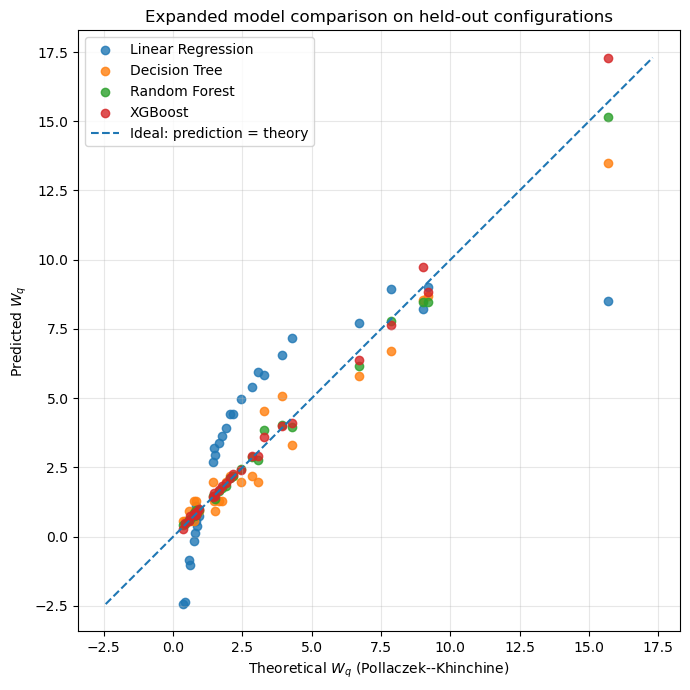

In [21]:

fig, ax = plt.subplots(figsize=(7, 7))

x = expanded_test_predictions["Wq_theory"]

ax.scatter(
    x,
    expanded_test_predictions["Wq_pred_LR"],
    label="Linear Regression",
    alpha=0.8,
)

ax.scatter(
    x,
    expanded_test_predictions["Wq_pred_DT"],
    label="Decision Tree",
    alpha=0.8,
)

ax.scatter(
    x,
    expanded_test_predictions["Wq_pred_RF"],
    label="Random Forest",
    alpha=0.8,
)

ax.scatter(
    x,
    expanded_test_predictions["Wq_pred_XGB"],
    label="XGBoost",
    alpha=0.8,
)


pred_cols = [
    "Wq_pred_LR",
    "Wq_pred_DT",
    "Wq_pred_RF",
    "Wq_pred_XGB",
]

lo = min(
    x.min(),
    expanded_test_predictions[
        pred_cols
    ].min().min(),
)

hi = max(
    x.max(),
    expanded_test_predictions[
        pred_cols
    ].max().max(),
)


ax.plot(
    [lo, hi],
    [lo, hi],
    linestyle="--",
    label="Ideal: prediction = theory",
)


ax.set_xlabel(
    r"Theoretical $W_q$ "
    r"(Pollaczek--Khinchine)"
)

ax.set_ylabel(
    r"Predicted $W_q$"
)

ax.set_title(
    "Expanded model comparison "
    "on held-out configurations"
)

ax.grid(alpha=0.3)
ax.legend()

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR
    / "mgi1_expanded_predicted_vs_theoretical_Wq.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()


### 11.4 Relative errors across $\rho$ and SCV


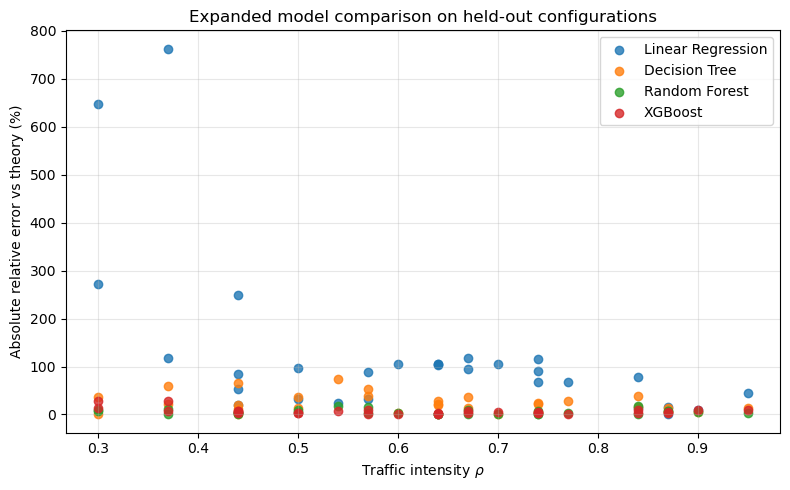

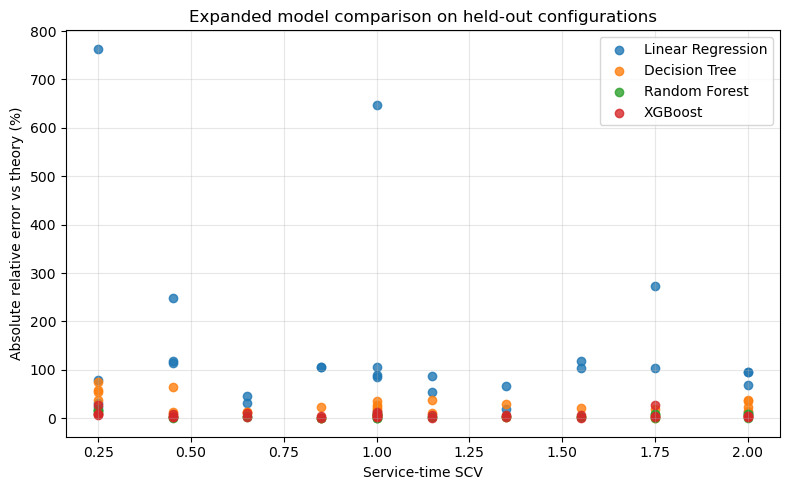

In [22]:

model_error_cols = {
    "Linear Regression":
        "Wq_rel_error_pct_LR_vs_theory",

    "Decision Tree":
        "Wq_rel_error_pct_DT_vs_theory",

    "Random Forest":
        "Wq_rel_error_pct_RF_vs_theory",

    "XGBoost":
        "Wq_rel_error_pct_XGB_vs_theory",
}


for x_col, x_label, filename in [

    (
        "rho",
        r"Traffic intensity $\rho$",
        "mgi1_expanded_relative_error_vs_rho.png",
    ),

    (
        "service_scv",
        "Service-time SCV",
        "mgi1_expanded_relative_error_vs_scv.png",
    ),
]:

    fig, ax = plt.subplots(figsize=(8, 5))

    for model_name, error_col in (
        model_error_cols.items()
    ):

        ax.scatter(
            expanded_test_predictions[x_col],
            expanded_test_predictions[
                error_col
            ],
            label=model_name,
            alpha=0.8,
        )


    ax.set_xlabel(x_label)

    ax.set_ylabel(
        "Absolute relative error "
        "vs theory (%)"
    )

    ax.set_title(
        "Expanded model comparison "
        "on held-out configurations"
    )

    ax.grid(alpha=0.3)
    ax.legend()

    fig.tight_layout()

    fig.savefig(
        OUTPUT_DIR / filename,
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()


## 12. Dataset-size adequacy and possible expansion

The 200-configuration grid is the **initial** stationary ML dataset, not an assumption that 200 rows must be sufficient. Dataset-size adequacy should be judged from training/validation behaviour and model stability, while the final test set remains reserved for final evaluation.

If flexible-model validation error is still materially improving as configuration coverage increases, the same design function can be expanded to approximately 300--400 configurations by adding denser $\rho$ and/or SCV grids. The simulator, replication aggregation, uncertainty calculation, configuration-level splitting, model-fitting logic, and evaluation metrics remain unchanged. Any expanded design should keep the same parameter ranges and preserve the original anchor values so that changes primarily reflect denser feature-space coverage.


### 12.1 Nested 200/300/400 configuration designs

Dataset-size adequacy is assessed by **increasing training-set coverage while keeping the existing validation and test configurations fixed**. This isolates the effect of adding configuration-level training observations from changes in evaluation difficulty.

- 200 configurations: 140 training + 30 validation + 30 test (existing experiment);
- 300 configurations: 240 training + the same 30 validation + the same 30 test;
- 400 configurations: 340 training + the same 30 validation + the same 30 test.

The additional configurations are selected from a denser candidate grid over the same parameter ranges. They are used only as additional training configurations. The original validation and test configurations are not replaced, and the test set is **not used to choose the dataset size**.


In [23]:
# ============================================================
# 12.1 Build two nested batches of 100 additional configurations
# ============================================================

BASE_DATASET_SIZE = len(configuration_design)  # 200 in the current experiment
TARGET_DATASET_SIZES = [BASE_DATASET_SIZE, 300, 400]

if BASE_DATASET_SIZE != 200:
    raise ValueError(
        "Section 12 is written to compare the completed 200-configuration "
        f"baseline with 300 and 400 configurations; got {BASE_DATASET_SIZE}."
    )

# A denser candidate grid over exactly the same parameter ranges.
# Existing 200 configurations are removed before new points are selected.
DENSE_RHO_GRID = np.round(np.linspace(0.30, 0.95, 61), 4)
DENSE_SCV_GRID = np.round(np.linspace(0.25, 2.00, 36), 4)

candidate_pool = (
    pd.MultiIndex.from_product(
        [DENSE_RHO_GRID, DENSE_SCV_GRID],
        names=["rho", "service_scv"],
    )
    .to_frame(index=False)
)

# Compare rounded numeric keys so that no completed 200-grid point is regenerated.
existing_keys = set(
    zip(
        configuration_design["rho"].round(4),
        configuration_design["service_scv"].round(4),
    )
)

candidate_pool["pair_key"] = list(
    zip(
        candidate_pool["rho"].round(4),
        candidate_pool["service_scv"].round(4),
    )
)

candidate_pool = candidate_pool[
    ~candidate_pool["pair_key"].isin(existing_keys)
].copy()

# Use the same coarse regions as the original configuration design so that
# the added points cover low/moderate/high queueing regimes rather than
# concentrating in one part of the feature space.
candidate_pool["rho_band"] = pd.cut(
    candidate_pool["rho"],
    bins=[0.299, 0.50, 0.70, 0.85, 0.951],
    labels=["low", "moderate", "high", "very_high"],
    include_lowest=True,
)

candidate_pool["scv_band"] = pd.cut(
    candidate_pool["service_scv"],
    bins=[0.249, 0.80, 1.40, 2.001],
    labels=["low", "moderate", "high"],
    include_lowest=True,
)

candidate_pool["stratum"] = (
    candidate_pool["rho_band"].astype(str)
    + "_"
    + candidate_pool["scv_band"].astype(str)
)

# Select exactly 200 new configurations, then divide them into two nested
# 100-configuration increments. Stratification keeps both increments broad.
extra_200, _ = train_test_split(
    candidate_pool,
    train_size=200,
    random_state=BASE_SEED + 1200,
    stratify=candidate_pool["stratum"],
)

extra_100_first, extra_100_second = train_test_split(
    extra_200,
    train_size=100,
    random_state=BASE_SEED + 1201,
    stratify=extra_200["stratum"],
)

extra_100_first = extra_100_first.copy().reset_index(drop=True)
extra_100_second = extra_100_second.copy().reset_index(drop=True)
extra_100_first["size_batch"] = "add_for_300"
extra_100_second["size_batch"] = "add_for_400"

extra_configurations = pd.concat(
    [extra_100_first, extra_100_second],
    ignore_index=True,
)

extra_configurations["config_id"] = [
    f"size_extra_{i:03d}" for i in range(len(extra_configurations))
]
extra_configurations["service_mean"] = SERVICE_MEAN
extra_configurations["lambda_rate"] = (
    extra_configurations["rho"] / SERVICE_MEAN
)
extra_configurations["warmup_time"] = SIM_WARMUP_TIME
extra_configurations["record_time"] = SIM_RECORD_TIME
extra_configurations["dt"] = DT
extra_configurations["split"] = "train"

# Exact PK benchmarks are stored for diagnostics only; they are not training labels.
extra_theory = pd.DataFrame([
    mgi1_theory(
        rho=float(row["rho"]),
        service_scv=float(row["service_scv"]),
        service_mean=SERVICE_MEAN,
    )
    for _, row in extra_configurations.iterrows()
])
extra_configurations["Wq_theory"] = extra_theory["Wq_theory"].to_numpy()
extra_configurations["Lq_theory"] = extra_theory["Lq_theory"].to_numpy()

extra_configurations.to_csv(
    OUTPUT_DIR / "mgi1_dataset_size_extra_configurations.csv",
    index=False,
)

print("Additional configurations by batch:")
print(extra_configurations["size_batch"].value_counts())
print("\nCoverage of added configurations:")
display(pd.crosstab(
    [extra_configurations["rho_band"], extra_configurations["scv_band"]],
    extra_configurations["size_batch"],
    dropna=False,
))


Additional configurations by batch:
size_batch
add_for_300    100
add_for_400    100
Name: count, dtype: int64

Coverage of added configurations:


size_batch          add_for_300  add_for_400
rho_band  scv_band                          
low       low                11           10
          moderate           10           10
          high               11           10
moderate  low                10           10
          moderate           10           10
          high               10           10
high      low                 8            7
          moderate            7            8
          high                8            7
very_high low                 5            6
          moderate            5            6
          high                5            6

### 12.2 Generate labels only for the additional configurations

The completed 200-configuration dataset is reused unchanged. Only the 200 new training configurations are simulated here. Each added configuration uses the same final simulation protocol: 10,000 warm-up time units, 40,000 recording time units, and 30 independent replications. The 30 replication-level estimates are again aggregated to one configuration-level stationary label with uncertainty recorded alongside it.


In [24]:
# ============================================================
# 12.2 Simulate only the 200 additional training configurations
# ============================================================

extra_frames = []
extra_sim_start = time.perf_counter()

for j, (_, cfg) in enumerate(extra_configurations.iterrows(), start=1):
    if j == 1 or j % 20 == 0 or j == len(extra_configurations):
        print(
            f"[{j}/{len(extra_configurations)}] {cfg['config_id']} "
            f"rho={cfg['rho']:.4f}, SCV={cfg['service_scv']:.4f}"
        )

    extra_frames.append(
        run_replications_for_config(
            config_id=cfg["config_id"],
            rho=float(cfg["rho"]),
            service_scv=float(cfg["service_scv"]),
            replications=N_REPLICATIONS,
            warmup_time=SIM_WARMUP_TIME,
            record_time=SIM_RECORD_TIME,
            seed_offset=60_000_000,
        )
    )

extra_replications = pd.concat(extra_frames, ignore_index=True)
extra_simulation_runtime_seconds = time.perf_counter() - extra_sim_start

extra_replications.to_csv(
    OUTPUT_DIR / "mgi1_dataset_size_extra_replications.csv",
    index=False,
)

extra_labels = aggregate_configuration_labels(extra_replications)
extra_labels = extra_labels.merge(
    extra_configurations[["config_id", "size_batch", "split"]],
    on="config_id",
    how="left",
    validate="one_to_one",
)

assert len(extra_labels) == 200
assert extra_labels["config_id"].is_unique

extra_labels.to_csv(
    OUTPUT_DIR / "mgi1_dataset_size_extra_labels.csv",
    index=False,
)

print(
    f"Additional 200 configuration labels generated in "
    f"{extra_simulation_runtime_seconds:.3f} seconds."
)

display(extra_labels.head())


[1/200] size_extra_000 rho=0.4950, SCV=1.1500
[20/200] size_extra_019 rho=0.8092, SCV=1.3000
[40/200] size_extra_039 rho=0.3000, SCV=1.9500
[60/200] size_extra_059 rho=0.8200, SCV=0.7500
[80/200] size_extra_079 rho=0.8092, SCV=0.4500
[100/200] size_extra_099 rho=0.9175, SCV=1.4000
[120/200] size_extra_119 rho=0.3867, SCV=1.4500
[140/200] size_extra_139 rho=0.3433, SCV=0.6000
[160/200] size_extra_159 rho=0.8092, SCV=1.2500
[180/200] size_extra_179 rho=0.8200, SCV=1.9000
[200/200] size_extra_199 rho=0.7875, SCV=1.6500
Additional 200 configuration labels generated in 6.209 seconds.


,config_id,rho,lambda_rate,service_mean,service_scv,warmup_time,record_time,n_replications,Wq_theory,Wq_sim_mean,...,Lq_theory,Lq_sim_from_Wq,Lq_ci95_low_from_Wq,Lq_ci95_high_from_Wq,lambda_hat_mean,service_mean_hat_mean,service_scv_hat_mean,mean_runtime_seconds_per_rep,size_batch,split
0,size_extra_000,0.4950,0.4950,1.0,1.15,10000.0,40000.0,30,1.053713,1.056397,...,0.521588,0.522917,0.515366,0.530467,0.495740,1.000868,1.151473,0.001005,add_for_300,train
1,size_extra_001,0.9283,0.9283,1.0,0.35,10000.0,40000.0,30,8.739226,8.914038,...,8.112623,8.274902,7.918093,8.631711,0.928947,1.000223,0.350656,0.001335,add_for_300,train
2,size_extra_002,0.5275,0.5275,1.0,0.80,10000.0,40000.0,30,1.004762,1.018277,...,0.530012,0.537141,0.528984,0.545298,0.527893,1.001646,0.801537,0.000784,add_for_300,train
3,size_extra_003,0.4842,0.4842,1.0,0.50,10000.0,40000.0,30,0.704052,0.710246,...,0.340902,0.343901,0.339845,0.347957,0.484597,1.001098,0.500428,0.000716,add_for_300,train
4,size_extra_004,0.4733,0.4733,1.0,0.45,10000.0,40000.0,30,0.651495,0.648342,...,0.308353,0.306860,0.302804,0.310916,0.472432,1.000606,0.450771,0.000698,add_for_300,train


### 12.3 Fixed-validation dataset-size comparison

The 30 validation configurations from the original experiment remain fixed for all three dataset sizes. Model settings are selected using this same validation set, exactly as in Sections 10--11. The final held-out test configurations are deliberately not used in this adequacy comparison.

The primary adequacy metric is validation RMSE against the simulation mean label. After each model has been selected using the simulation labels, performance against the exact PK value is also recorded as a diagnostic benchmark.


In [25]:
# ============================================================
# 12.3 Build nested training sets: 140 -> 240 -> 340 rows
# ============================================================

baseline_labels = pd.read_csv(
    OUTPUT_DIR / f"mgi1_stationary_{N_CONFIGURATIONS}_labels.csv"
)

base_train_size = baseline_labels[
    baseline_labels["split"] == "train"
].copy()
fixed_validation_size = baseline_labels[
    baseline_labels["split"] == "validation"
].copy()
fixed_test_size = baseline_labels[
    baseline_labels["split"] == "test"
].copy()

extra_for_300 = extra_labels[
    extra_labels["size_batch"] == "add_for_300"
].copy()
extra_for_400 = extra_labels[
    extra_labels["size_batch"] == "add_for_400"
].copy()

training_sets_by_total_size = {
    200: base_train_size.copy(),
    300: pd.concat(
        [base_train_size, extra_for_300],
        ignore_index=True,
    ),
    400: pd.concat(
        [base_train_size, extra_for_300, extra_for_400],
        ignore_index=True,
    ),
}

expected_training_sizes = {200: 140, 300: 240, 400: 340}
for total_size, expected_n in expected_training_sizes.items():
    actual_n = len(training_sets_by_total_size[total_size])
    assert actual_n == expected_n, (
        f"Expected {expected_n} training configurations for total size "
        f"{total_size}, got {actual_n}."
    )

# The evaluation cases are exactly unchanged across all dataset sizes.
assert len(fixed_validation_size) == 30
assert len(fixed_test_size) == 30

print("Training configurations used in the size experiment:")
for total_size, train_size_df in training_sets_by_total_size.items():
    print(
        f"  total design {total_size}: "
        f"{len(train_size_df)} train + "
        f"{len(fixed_validation_size)} fixed validation + "
        f"{len(fixed_test_size)} fixed test"
    )


Training configurations used in the size experiment:
  total design 200: 140 train + 30 fixed validation + 30 fixed test
  total design 300: 240 train + 30 fixed validation + 30 fixed test
  total design 400: 340 train + 30 fixed validation + 30 fixed test


In [26]:
# ============================================================
# 12.3 Fit/tune all four models for each training-set size
# ============================================================

def choose_best_candidate(model_family, candidates, X_train_local, y_train_local,
                          X_val_local, y_val_local):
    """Choose settings using validation RMSE against simulation labels only."""
    rows = []

    for params in candidates:
        if model_family == "Decision Tree":
            model = DecisionTreeRegressor(
                random_state=BASE_SEED,
                **params,
            )
        elif model_family == "Random Forest":
            model = RandomForestRegressor(
                random_state=BASE_SEED,
                n_jobs=-1,
                **params,
            )
        elif model_family == "XGBoost":
            model = XGBRegressor(
                objective="reg:squarederror",
                random_state=BASE_SEED,
                n_jobs=-1,
                subsample=1.0,
                colsample_bytree=1.0,
                **params,
            )
        else:
            raise ValueError(f"Unknown model family: {model_family}")

        start = time.perf_counter()
        model.fit(X_train_local, y_train_local)
        training_seconds = time.perf_counter() - start
        pred = model.predict(X_val_local)

        rows.append({
            **params,
            "validation_RMSE_vs_sim_label": rmse(y_val_local, pred),
            "training_seconds": training_seconds,
        })

    search_df = (
        pd.DataFrame(rows)
        .sort_values("validation_RMSE_vs_sim_label")
        .reset_index(drop=True)
    )
    return search_df.iloc[0].to_dict(), search_df


def model_from_selected_settings(model_name, selected):
    if model_name == "Decision Tree":
        return DecisionTreeRegressor(
            random_state=BASE_SEED,
            max_depth=(
                None if pd.isna(selected["max_depth"])
                else int(selected["max_depth"])
            ),
            min_samples_leaf=int(selected["min_samples_leaf"]),
        )

    if model_name == "Random Forest":
        return RandomForestRegressor(
            random_state=BASE_SEED,
            n_jobs=-1,
            n_estimators=int(selected["n_estimators"]),
            max_depth=(
                None if pd.isna(selected["max_depth"])
                else int(selected["max_depth"])
            ),
            min_samples_leaf=int(selected["min_samples_leaf"]),
        )

    if model_name == "XGBoost":
        return XGBRegressor(
            objective="reg:squarederror",
            random_state=BASE_SEED,
            n_jobs=-1,
            subsample=1.0,
            colsample_bytree=1.0,
            n_estimators=int(selected["n_estimators"]),
            max_depth=int(selected["max_depth"]),
            learning_rate=float(selected["learning_rate"]),
        )

    raise ValueError(f"Unknown model name: {model_name}")


size_metric_rows = []
size_prediction_rows = []
size_setting_rows = []
size_search_rows = []

X_val_size = fixed_validation_size[feature_cols]
y_val_sim_size = fixed_validation_size[target_col].to_numpy()
y_val_theory_size = fixed_validation_size["Wq_theory"].to_numpy()

for total_size in [200, 300, 400]:
    train_size_df = training_sets_by_total_size[total_size]
    X_train_size = train_size_df[feature_cols]
    y_train_size = train_size_df[target_col]

    print(
        f"\nDataset-size experiment: total={total_size}, "
        f"training rows={len(train_size_df)}"
    )

    # --------------------------------------------------------
    # Linear Regression: no hyperparameter search
    # --------------------------------------------------------
    lr_size = LinearRegression()
    start = time.perf_counter()
    lr_size.fit(X_train_size, y_train_size)
    lr_train_seconds = time.perf_counter() - start
    lr_val_pred_size = lr_size.predict(X_val_size)

    size_setting_rows.append({
        "total_configurations": total_size,
        "n_training_configurations": len(train_size_df),
        "Model": "Linear Regression",
        "selected_settings": "raw rho + SCV; no tuning",
    })

    # --------------------------------------------------------
    # Decision Tree, Random Forest, XGBoost:
    # same candidate grids as the main experiment
    # --------------------------------------------------------
    selected_models = {
        "Linear Regression": (lr_size, lr_val_pred_size, lr_train_seconds),
    }

    for model_name, candidates in [
        ("Decision Tree", dt_candidates),
        ("Random Forest", rf_candidates),
        ("XGBoost", xgb_candidates),
    ]:
        selected, search_df = choose_best_candidate(
            model_family=model_name,
            candidates=candidates,
            X_train_local=X_train_size,
            y_train_local=y_train_size,
            X_val_local=X_val_size,
            y_val_local=y_val_sim_size,
        )

        search_df = search_df.copy()
        search_df.insert(0, "Model", model_name)
        search_df.insert(0, "total_configurations", total_size)
        size_search_rows.append(search_df)

        final_size_model = model_from_selected_settings(model_name, selected)
        start = time.perf_counter()
        final_size_model.fit(X_train_size, y_train_size)
        selected_train_seconds = time.perf_counter() - start
        val_pred_size = final_size_model.predict(X_val_size)

        selected_models[model_name] = (
            final_size_model,
            val_pred_size,
            selected_train_seconds,
        )

        selected_clean = {
            k: v for k, v in selected.items()
            if k not in {"validation_RMSE_vs_sim_label", "training_seconds"}
        }
        size_setting_rows.append({
            "total_configurations": total_size,
            "n_training_configurations": len(train_size_df),
            "Model": model_name,
            "selected_settings": json.dumps(selected_clean, sort_keys=True),
        })

    # --------------------------------------------------------
    # Record validation performance against both references.
    # Selection above used simulation labels only.
    # --------------------------------------------------------
    for model_name, (_, pred_size, training_seconds) in selected_models.items():
        sim_metrics = regression_metrics(y_val_sim_size, pred_size)
        theory_metrics = regression_metrics(y_val_theory_size, pred_size)

        size_metric_rows.append({
            "total_configurations": total_size,
            "n_training_configurations": len(train_size_df),
            "Model": model_name,
            "Reference": "simulation mean label",
            "training_seconds": training_seconds,
            **sim_metrics,
        })

        size_metric_rows.append({
            "total_configurations": total_size,
            "n_training_configurations": len(train_size_df),
            "Model": model_name,
            "Reference": "PK theory (diagnostic only)",
            "training_seconds": training_seconds,
            **theory_metrics,
        })

        for row_idx, (_, val_row) in enumerate(fixed_validation_size.iterrows()):
            size_prediction_rows.append({
                "total_configurations": total_size,
                "n_training_configurations": len(train_size_df),
                "Model": model_name,
                "config_id": val_row["config_id"],
                "rho": val_row["rho"],
                "service_scv": val_row["service_scv"],
                "Wq_sim_mean": val_row["Wq_sim_mean"],
                "Wq_theory": val_row["Wq_theory"],
                "Wq_prediction": float(pred_size[row_idx]),
            })


dataset_size_metrics = pd.DataFrame(size_metric_rows)
dataset_size_predictions = pd.DataFrame(size_prediction_rows)
dataset_size_settings = pd.DataFrame(size_setting_rows)
dataset_size_search = pd.concat(size_search_rows, ignore_index=True)

dataset_size_metrics.to_csv(
    OUTPUT_DIR / "mgi1_dataset_size_validation_metrics.csv",
    index=False,
)
dataset_size_predictions.to_csv(
    OUTPUT_DIR / "mgi1_dataset_size_validation_predictions.csv",
    index=False,
)
dataset_size_settings.to_csv(
    OUTPUT_DIR / "mgi1_dataset_size_chosen_settings.csv",
    index=False,
)
dataset_size_search.to_csv(
    OUTPUT_DIR / "mgi1_dataset_size_validation_searches.csv",
    index=False,
)

print("\nPrimary dataset-size comparison: validation RMSE vs simulation labels")
size_rmse_table = (
    dataset_size_metrics[
        dataset_size_metrics["Reference"] == "simulation mean label"
    ]
    .pivot(
        index="Model",
        columns="total_configurations",
        values="RMSE",
    )
)
display(size_rmse_table.round(6))



Dataset-size experiment: total=200, training rows=140

Dataset-size experiment: total=300, training rows=240

Dataset-size experiment: total=400, training rows=340

Primary dataset-size comparison: validation RMSE vs simulation labels


total_configurations,200,300,400
Model,,,
Decision Tree,0.881741,0.921488,1.013229
Linear Regression,2.456282,2.457326,2.435777
Random Forest,1.001872,0.760204,0.875032
XGBoost,0.328209,0.189412,0.250208


### 12.4 Adequacy and model-stability diagnostics

Two complementary diagnostics are reported:

1. **Validation-error change:** whether RMSE continues to decrease materially as the training coverage grows from 200 to 300 to 400 total configurations.
2. **Prediction stability:** how much a model's predictions on the same fixed validation configurations move when more training configurations are added.

No automatic threshold is imposed. A dataset size is considered more convincing when flexible-model validation error begins to plateau and prediction shifts become small. Model ranking should also be interpreted cautiously if it changes across dataset sizes.


In [27]:
# ============================================================
# 12.4 Quantify validation improvement and prediction stability
# ============================================================

primary_size_metrics = (
    dataset_size_metrics[
        dataset_size_metrics["Reference"] == "simulation mean label"
    ]
    .copy()
    .sort_values(["Model", "total_configurations"])
)

improvement_rows = []
for model_name, g in primary_size_metrics.groupby("Model"):
    g = g.sort_values("total_configurations").reset_index(drop=True)
    for i in range(1, len(g)):
        prev = g.iloc[i - 1]
        curr = g.iloc[i]
        improvement_rows.append({
            "Model": model_name,
            "from_total_configurations": int(prev["total_configurations"]),
            "to_total_configurations": int(curr["total_configurations"]),
            "RMSE_previous": float(prev["RMSE"]),
            "RMSE_current": float(curr["RMSE"]),
            "RMSE_relative_improvement_pct": (
                100.0 * (float(prev["RMSE"]) - float(curr["RMSE"]))
                / float(prev["RMSE"])
            ),
        })

size_rmse_improvement = pd.DataFrame(improvement_rows)

stability_rows = []
for model_name in dataset_size_predictions["Model"].unique():
    model_pred = dataset_size_predictions[
        dataset_size_predictions["Model"] == model_name
    ].copy()

    wide = model_pred.pivot(
        index="config_id",
        columns="total_configurations",
        values="Wq_prediction",
    )

    for previous_size, current_size in [(200, 300), (300, 400)]:
        diff = (
            wide[current_size].to_numpy(dtype=float)
            - wide[previous_size].to_numpy(dtype=float)
        )
        stability_rows.append({
            "Model": model_name,
            "from_total_configurations": previous_size,
            "to_total_configurations": current_size,
            "prediction_shift_RMSE": float(np.sqrt(np.mean(diff**2))),
            "prediction_shift_MAE": float(np.mean(np.abs(diff))),
            "prediction_shift_max_abs": float(np.max(np.abs(diff))),
        })

prediction_stability = pd.DataFrame(stability_rows)

size_rmse_improvement.to_csv(
    OUTPUT_DIR / "mgi1_dataset_size_rmse_improvement.csv",
    index=False,
)
prediction_stability.to_csv(
    OUTPUT_DIR / "mgi1_dataset_size_prediction_stability.csv",
    index=False,
)

print("Validation RMSE improvement as configuration coverage increases:")
display(size_rmse_improvement.round(6))

print("Prediction stability on the same 30 validation configurations:")
display(prediction_stability.round(6))


Validation RMSE improvement as configuration coverage increases:


,Model,from_total_configurations,to_total_configurations,RMSE_previous,RMSE_current,RMSE_relative_improvement_pct
0,Decision Tree,200,300,0.881741,0.921488,-4.507747
1,Decision Tree,300,400,0.921488,1.013229,-9.955766
2,Linear Regression,200,300,2.456282,2.457326,-0.042524
3,Linear Regression,300,400,2.457326,2.435777,0.876937
4,Random Forest,200,300,1.001872,0.760204,24.121682
5,Random Forest,300,400,0.760204,0.875032,-15.104903
6,XGBoost,200,300,0.328209,0.189412,42.289191
7,XGBoost,300,400,0.189412,0.250208,-32.097128


Prediction stability on the same 30 validation configurations:


,Model,from_total_configurations,to_total_configurations,prediction_shift_RMSE,prediction_shift_MAE,prediction_shift_max_abs
0,Linear Regression,200,300,0.260781,0.203464,0.513203
1,Linear Regression,300,400,0.148874,0.121644,0.300515
2,Decision Tree,200,300,0.526933,0.314714,2.097737
3,Decision Tree,300,400,0.705490,0.201299,3.818872
4,Random Forest,200,300,0.471503,0.188128,2.079680
5,Random Forest,300,400,0.222813,0.098006,0.970705
6,XGBoost,200,300,0.294429,0.111803,1.546342
7,XGBoost,300,400,0.195385,0.099776,0.826497


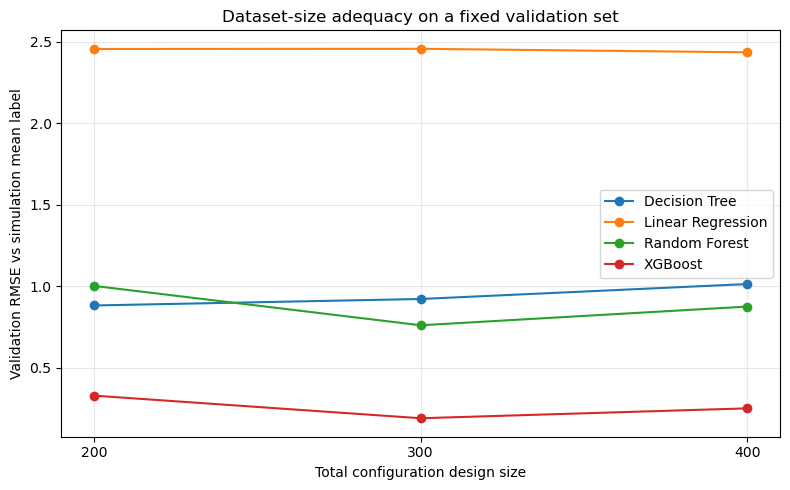

In [28]:
# ============================================================
# 12.4 Plot: validation RMSE versus total configuration coverage
# ============================================================

plot_size_metrics = primary_size_metrics.copy()

fig, ax = plt.subplots(figsize=(8, 5))

for model_name, g in plot_size_metrics.groupby("Model"):
    g = g.sort_values("total_configurations")
    ax.plot(
        g["total_configurations"],
        g["RMSE"],
        marker="o",
        label=model_name,
    )

ax.set_xticks([200, 300, 400])
ax.set_xlabel("Total configuration design size")
ax.set_ylabel("Validation RMSE vs simulation mean label")
ax.set_title("Dataset-size adequacy on a fixed validation set")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "mgi1_dataset_size_validation_rmse.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()


### 12.5 Interpretation rule for the next step

Use the validation results above to decide whether the initial 200-configuration design is adequate or whether denser coverage is justified. The decision should be based on the **pattern** across 200, 300, and 400 configurations rather than on a single small difference:

- if flexible-model validation RMSE changes little and prediction shifts are already small, the smaller design is adequate for this two-input experiment;
- if RMSE continues to improve materially or model predictions/rankings remain unstable, retain the larger configuration design;
- the held-out test set should be used only after the dataset-size decision has been made, so that dataset size is not selected from final-test performance.

This section changes only the amount of configuration-level training coverage. The simulation protocol, replication aggregation, uncertainty calculation, target definition, feature set, validation cases, candidate model families, and evaluation metrics remain unchanged.


### 12.6 Final 300-configuration simulation vs theoretical Wq

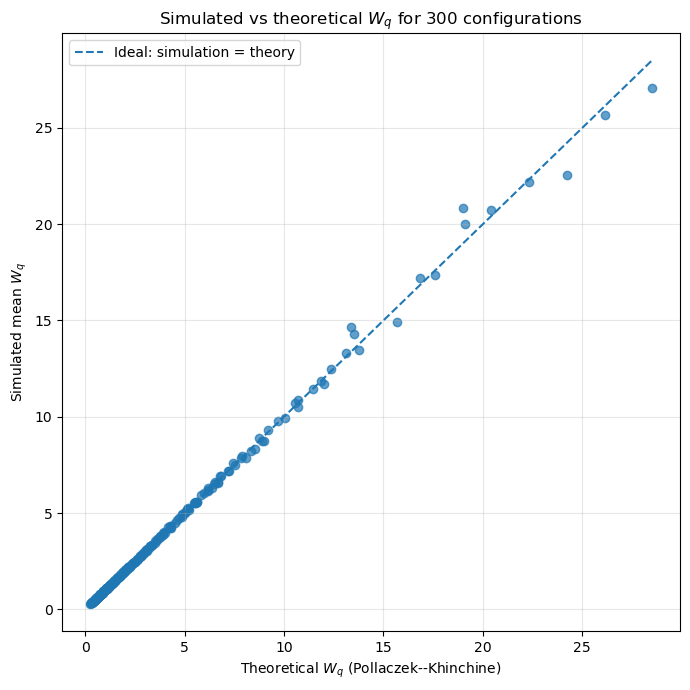

In [29]:
# ============================================================
# 12.6 Final 300-configurations:
# simulated Wq vs theoretical Wq
# ============================================================

# Combine all 300 configurations:
# original 200 + first 100 additional configurations
final_labels_300 = pd.concat(
    [
        baseline_labels,
        extra_for_300
    ],
    ignore_index=True,
)

assert len(final_labels_300) == 300
assert final_labels_300["config_id"].is_unique


# ------------------------------------------------------------
# Plot simulated Wq against PK theoretical Wq
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(7, 7))

ax.scatter(
    final_labels_300["Wq_theory"],
    final_labels_300["Wq_sim_mean"],
    alpha=0.7,
)

# Ideal agreement line: y = x
lo = min(
    final_labels_300["Wq_theory"].min(),
    final_labels_300["Wq_sim_mean"].min(),
)

hi = max(
    final_labels_300["Wq_theory"].max(),
    final_labels_300["Wq_sim_mean"].max(),
)

ax.plot(
    [lo, hi],
    [lo, hi],
    linestyle="--",
    label="Ideal: simulation = theory",
)

ax.set_xlabel(
    r"Theoretical $W_q$ (Pollaczek--Khinchine)"
)

ax.set_ylabel(
    r"Simulated mean $W_q$"
)

ax.set_title(
    r"Simulated vs theoretical $W_q$ "
    "for 300 configurations"
)

ax.grid(alpha=0.3)
ax.legend()

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "mgi1_300_simulated_vs_theoretical_Wq.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [30]:
# ============================================================
# Summary of simulation accuracy for the final 300 configs
# ============================================================

mean_rel_error = (
    final_labels_300["Wq_rel_error_vs_theory_pct"].mean()
)

median_rel_error = (
    final_labels_300["Wq_rel_error_vs_theory_pct"].median()
)

p95_rel_error = (
    final_labels_300["Wq_rel_error_vs_theory_pct"].quantile(0.95)
)

ci_coverage = (
    (
        (final_labels_300["Wq_theory"]
         >= final_labels_300["Wq_ci95_low"])
        &
        (final_labels_300["Wq_theory"]
         <= final_labels_300["Wq_ci95_high"])
    ).mean() * 100
)

print(f"Mean absolute relative error: {mean_rel_error:.2f}%")
print(f"Median absolute relative error: {median_rel_error:.2f}%")
print(f"95th percentile relative error: {p95_rel_error:.2f}%")
print(f"95% CI coverage: {ci_coverage:.1f}%")

Mean absolute relative error: 0.86%
Median absolute relative error: 0.58%
95th percentile relative error: 2.14%
95% CI coverage: 96.7%


## 13. Final held-out evaluation for the selected 300-configuration design

The dataset-size adequacy study in Section 12 selected **300 total configurations** using the fixed validation set only. The final model is therefore refit using the 240 training configurations plus the same 30 validation configurations, giving 270 development configurations in total. Hyperparameters are fixed at the settings selected for the 300-configuration design.

The original 30 test configurations remain unchanged and are used only here for the final held-out evaluation. Performance is reported against both the simulation mean label and the exact Pollaczek--Khinchine benchmark. The theoretical values remain diagnostic references and are not used for model fitting or hyperparameter selection.


### 13.1 Prepare the final 300-configuration development/test sets

In [31]:
# ============================================================
# 13.1 Prepare the final 300-configuration development/test sets
# ============================================================

FINAL_DATASET_SIZE = 300

if FINAL_DATASET_SIZE not in training_sets_by_total_size:
    raise ValueError(
        f"Dataset size {FINAL_DATASET_SIZE} is not available in Section 12."
    )

# Dataset size has already been selected from validation behaviour only.
final_train_300 = training_sets_by_total_size[FINAL_DATASET_SIZE].copy()
final_validation_300 = fixed_validation_size.copy()
final_test_300 = fixed_test_size.copy()

# Refit on train + validation after all design/hyperparameter decisions are fixed.
final_development_300 = pd.concat(
    [final_train_300, final_validation_300],
    ignore_index=True,
)

assert len(final_train_300) == 240
assert len(final_validation_300) == 30
assert len(final_development_300) == 270
assert len(final_test_300) == 30

# Ensure the final held-out configurations were not used for refitting.
assert set(final_development_300["config_id"]).isdisjoint(
    set(final_test_300["config_id"])
)

# Hyperparameters fixed from the 300-configuration validation search.
settings_300 = (
    dataset_size_settings[
        dataset_size_settings["total_configurations"] == FINAL_DATASET_SIZE
    ]
    .copy()
    .reset_index(drop=True)
)

assert set(settings_300["Model"]) == {
    "Linear Regression",
    "Decision Tree",
    "Random Forest",
    "XGBoost",
}

settings_300.to_csv(
    OUTPUT_DIR / "mgi1_final_300_selected_settings.csv",
    index=False,
)

print(
    f"Final design: {len(final_development_300)} development "
    f"(train + validation) + {len(final_test_300)} held-out test configurations."
)
display(settings_300)


Final design: 270 development (train + validation) + 30 held-out test configurations.


,total_configurations,n_training_configurations,Model,selected_settings
0,300,240,Linear Regression,raw rho + SCV; no tuning
1,300,240,Decision Tree,"{""max_depth"": 5.0, ""min_samples_leaf"": 1.0}"
2,300,240,Random Forest,"{""max_depth"": NaN, ""min_samples_leaf"": 1.0, ""n..."
3,300,240,XGBoost,"{""learning_rate"": 0.03, ""max_depth"": 3.0, ""n_e..."


### 13.2 Refit the four final models and evaluate once on test


In [32]:
# ============================================================
# 13.2 Refit the four final models and evaluate once on test
# ============================================================

def _settings_dict_for_300(model_name):
    row = settings_300.loc[
        settings_300["Model"] == model_name,
        "selected_settings",
    ].iloc[0]

    if model_name == "Linear Regression":
        return {}

    return json.loads(row)


X_dev_300 = final_development_300[feature_cols]
y_dev_300 = final_development_300[target_col]

X_test_300 = final_test_300[feature_cols]
y_test_sim_300 = final_test_300[target_col].to_numpy()
y_test_theory_300 = final_test_300["Wq_theory"].to_numpy()

final_models_300 = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": model_from_selected_settings(
        "Decision Tree",
        _settings_dict_for_300("Decision Tree"),
    ),
    "Random Forest": model_from_selected_settings(
        "Random Forest",
        _settings_dict_for_300("Random Forest"),
    ),
    "XGBoost": model_from_selected_settings(
        "XGBoost",
        _settings_dict_for_300("XGBoost"),
    ),
}

final_300_predictions = {}
final_300_training_times = {}
final_300_prediction_times = {}

for model_name, model in final_models_300.items():
    start = time.perf_counter()
    model.fit(X_dev_300, y_dev_300)
    final_300_training_times[model_name] = time.perf_counter() - start

    # Final prediction used for the performance metrics.
    pred = model.predict(X_test_300)
    final_300_predictions[model_name] = pred

    # Prediction timing is measured separately from training.
    start = time.perf_counter()
    for _ in range(50):
        _ = model.predict(X_test_300)
    final_300_prediction_times[model_name] = (
        time.perf_counter() - start
    ) / 50.0


# ------------------------------------------------------------
# Final held-out metrics
# ------------------------------------------------------------

final_metric_rows = []

for model_name, pred in final_300_predictions.items():
    final_metric_rows.append({
        "Model": model_name,
        "Reference": "simulation mean label",
        **regression_metrics(y_test_sim_300, pred),
    })

    final_metric_rows.append({
        "Model": model_name,
        "Reference": "PK theory",
        **regression_metrics(y_test_theory_300, pred),
    })

final_300_test_metrics = pd.DataFrame(final_metric_rows)

final_300_test_metrics.to_csv(
    OUTPUT_DIR / "mgi1_final_300_test_metrics.csv",
    index=False,
)


# ------------------------------------------------------------
# Configuration-level final predictions and errors
# ------------------------------------------------------------

final_300_test_predictions = final_test_300[
    [
        "config_id",
        "rho",
        "lambda_rate",
        "service_scv",
        "Wq_sim_mean",
        "Wq_theory",
        "Wq_ci95_low",
        "Wq_ci95_high",
        "Wq_relative_ci_halfwidth_pct",
    ]
].copy()

short_names = {
    "Linear Regression": "LR",
    "Decision Tree": "DT",
    "Random Forest": "RF",
    "XGBoost": "XGB",
}

for model_name, pred in final_300_predictions.items():
    short = short_names[model_name]

    final_300_test_predictions[f"Wq_pred_{short}"] = pred
    final_300_test_predictions[f"Lq_pred_{short}"] = (
        final_300_test_predictions["lambda_rate"] * pred
    )

    # Error relative to exact PK theory.
    final_300_test_predictions[
        f"Wq_abs_error_{short}_vs_theory"
    ] = (
        final_300_test_predictions[f"Wq_pred_{short}"]
        - final_300_test_predictions["Wq_theory"]
    ).abs()

    final_300_test_predictions[
        f"Wq_rel_error_pct_{short}_vs_theory"
    ] = (
        100.0
        * final_300_test_predictions[
            f"Wq_abs_error_{short}_vs_theory"
        ]
        / final_300_test_predictions["Wq_theory"].abs()
    )

    # Error relative to the simulation label actually learned by the model.
    final_300_test_predictions[
        f"Wq_abs_error_{short}_vs_sim"
    ] = (
        final_300_test_predictions[f"Wq_pred_{short}"]
        - final_300_test_predictions["Wq_sim_mean"]
    ).abs()

    final_300_test_predictions[
        f"Wq_rel_error_pct_{short}_vs_sim"
    ] = (
        100.0
        * final_300_test_predictions[
            f"Wq_abs_error_{short}_vs_sim"
        ]
        / final_300_test_predictions["Wq_sim_mean"].abs()
    )

final_300_test_predictions.to_csv(
    OUTPUT_DIR / "mgi1_final_300_test_predictions.csv",
    index=False,
)


# ------------------------------------------------------------
# Training and prediction timing kept separate
# ------------------------------------------------------------

final_300_timing = pd.DataFrame([
    {
        "Model": model_name,
        "training_seconds": final_300_training_times[model_name],
        "prediction_seconds_for_30_test_configs": final_300_prediction_times[model_name],
    }
    for model_name in final_models_300
])

final_300_timing.to_csv(
    OUTPUT_DIR / "mgi1_final_300_timing.csv",
    index=False,
)

print("Final 300-configuration held-out test metrics:")
display(final_300_test_metrics.round(6))

print("Final model timing:")
display(final_300_timing.round(6))


Final 300-configuration held-out test metrics:


,Model,Reference,MAE,RMSE,R2,MAPE_pct,Median_APE_pct
0,Linear Regression,simulation mean label,1.615866,2.067431,0.608698,114.006138,82.201914
1,Linear Regression,PK theory,1.647116,2.157895,0.597829,114.510929,81.887313
2,Decision Tree,simulation mean label,0.454251,0.647381,0.961632,19.983117,18.506066
3,Decision Tree,PK theory,0.483919,0.711363,0.956295,20.136582,19.350199
4,Random Forest,simulation mean label,0.145889,0.273232,0.993165,4.966624,3.740342
5,Random Forest,PK theory,0.176191,0.341753,0.989913,5.122957,3.275581
6,XGBoost,simulation mean label,0.149006,0.246597,0.994433,6.818737,3.761586
7,XGBoost,PK theory,0.153914,0.304144,0.992011,6.614498,3.562154


Final model timing:


,Model,training_seconds,prediction_seconds_for_30_test_configs
0,Linear Regression,0.000641,0.000145
1,Decision Tree,0.000601,0.000152
2,Random Forest,0.112820,0.013478
3,XGBoost,0.029130,0.000249


### 13.3 Final predictions versus the analytical benchmark

The plot below is the final held-out comparison after dataset size and hyperparameters have already been fixed. The 30 test configurations are the same untouched configurations reserved in the original split.


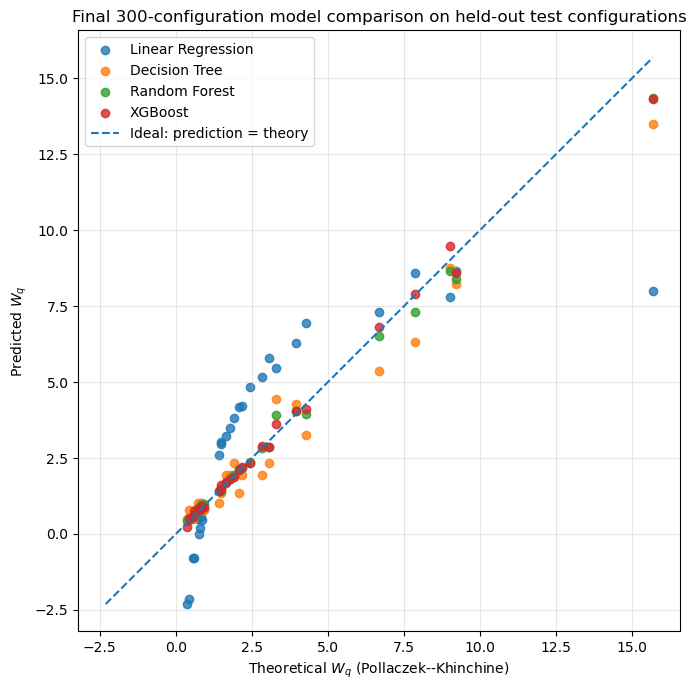

In [33]:
# ============================================================
# 13.3 Final predicted-versus-theoretical Wq plot
# ============================================================

fig, ax = plt.subplots(figsize=(7, 7))

x = final_300_test_predictions["Wq_theory"]

for model_name, short in short_names.items():
    ax.scatter(
        x,
        final_300_test_predictions[f"Wq_pred_{short}"],
        label=model_name,
        alpha=0.8,
    )

pred_cols_300 = [
    f"Wq_pred_{short}" for short in short_names.values()
]

lo = min(
    x.min(),
    final_300_test_predictions[pred_cols_300].min().min(),
)
hi = max(
    x.max(),
    final_300_test_predictions[pred_cols_300].max().max(),
)

ax.plot(
    [lo, hi],
    [lo, hi],
    linestyle="--",
    label="Ideal: prediction = theory",
)

ax.set_xlabel(
    r"Theoretical $W_q$ (Pollaczek--Khinchine)"
)
ax.set_ylabel(r"Predicted $W_q$")
ax.set_title(
    "Final 300-configuration model comparison "
    "on held-out test configurations"
)
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "mgi1_final_300_predicted_vs_theoretical_Wq.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()


### 13.4 Final relative-error diagnostics across utilisation and SCV

These plots retain the supervisor-requested interpretation by traffic intensity and service-time variability, now using the final 300-configuration design.


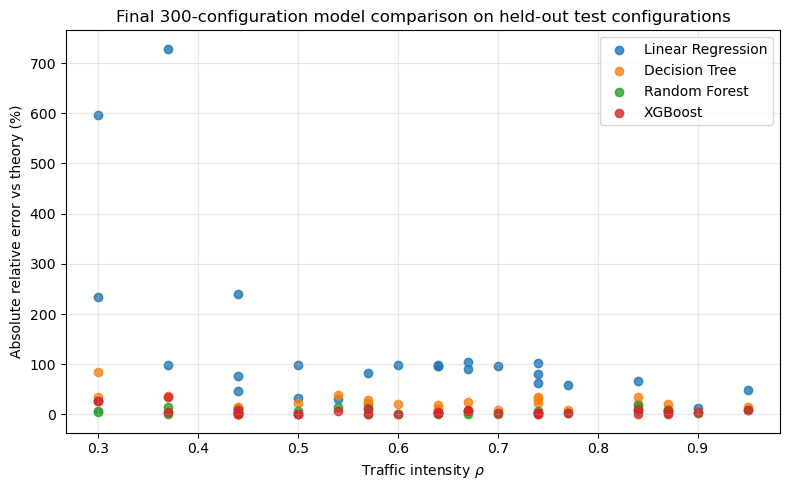

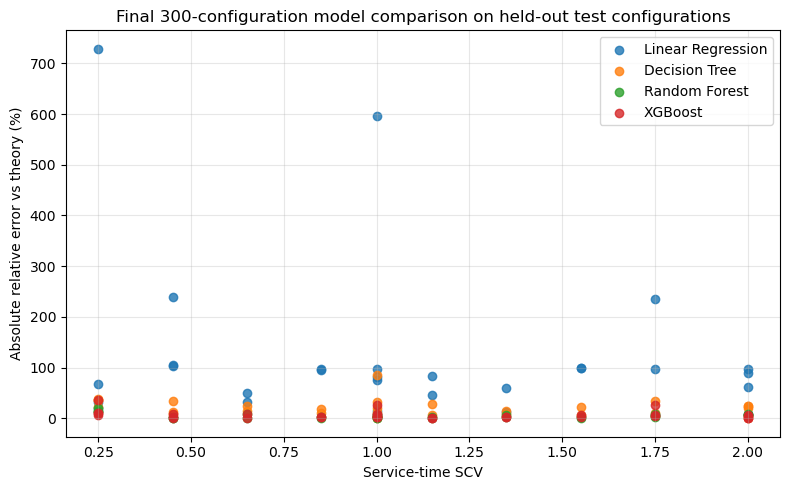

,Model,MAE,RMSE,R2,MAPE_pct,Median_APE_pct
0,Linear Regression,1.6471,2.1579,0.5978,114.5109,81.8873
1,Decision Tree,0.4839,0.7114,0.9563,20.1366,19.3502
2,Random Forest,0.1762,0.3418,0.9899,5.1230,3.2756
3,XGBoost,0.1539,0.3041,0.9920,6.6145,3.5622


In [34]:
# ============================================================
# 13.4 Final relative error across rho and SCV
# ============================================================

final_error_cols_300 = {
    model_name: f"Wq_rel_error_pct_{short}_vs_theory"
    for model_name, short in short_names.items()
}

for x_col, x_label, filename in [
    (
        "rho",
        r"Traffic intensity $\rho$",
        "mgi1_final_300_relative_error_vs_rho.png",
    ),
    (
        "service_scv",
        "Service-time SCV",
        "mgi1_final_300_relative_error_vs_scv.png",
    ),
]:
    fig, ax = plt.subplots(figsize=(8, 5))

    for model_name, error_col in final_error_cols_300.items():
        ax.scatter(
            final_300_test_predictions[x_col],
            final_300_test_predictions[error_col],
            label=model_name,
            alpha=0.8,
        )

    ax.set_xlabel(x_label)
    ax.set_ylabel("Absolute relative error vs theory (%)")
    ax.set_title(
        "Final 300-configuration model comparison "
        "on held-out test configurations"
    )
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()

    fig.savefig(
        OUTPUT_DIR / filename,
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()


# Compact final theory-comparison table for reporting.
final_300_theory_comparison = (
    final_300_test_metrics[
        final_300_test_metrics["Reference"] == "PK theory"
    ]
    .copy()
    .reset_index(drop=True)
)

final_300_theory_comparison.to_csv(
    OUTPUT_DIR / "mgi1_final_300_model_comparison_vs_theory.csv",
    index=False,
)

display(
    final_300_theory_comparison[
        [
            "Model",
            "MAE",
            "RMSE",
            "R2",
            "MAPE_pct",
            "Median_APE_pct",
        ]
    ].round(4)
)
